In [3]:
import random

import numpy as np
import json
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn import svm
from sklearn.linear_model import SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score
import os
import time
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, cohen_kappa_score
from sklearn.metrics import ConfusionMatrixDisplay

class Results:
    accuracy = pd.DataFrame()
    precision = pd.DataFrame()
    recall = pd.DataFrame()
    f1 = pd.DataFrame()
    kappa = pd.DataFrame()
    train_accuracy = pd.DataFrame()
    train_precision = pd.DataFrame()
    train_recall = pd.DataFrame()
    train_f1 = pd.DataFrame()
    train_kappa = pd.DataFrame()
    cv_mean = pd.DataFrame()
    cv_stddev = pd.DataFrame()
    train_error_rate = pd.DataFrame()
    gap = pd.DataFrame()
    error_rate = pd.DataFrame()
    train_time = pd.DataFrame()
    infer_time = pd.DataFrame()

    accuracy["Setup"] = ""
    precision["Setup"] = ""
    recall["Setup"] = ""
    f1["Setup"] = ""
    cv_mean["Setup"] = ""
    cv_stddev["Setup"] = ""
    kappa["Setup"] = ""
    error_rate["Setup"] = ""
    train_time["Setup"] = ""
    infer_time["Setup"] = ""
    train_accuracy["Setup"] = ""
    train_precision["Setup"] = ""
    train_recall["Setup"] = ""
    train_f1["Setup"] = ""
    train_kappa["Setup"] = ""
    train_error_rate["Setup"] = ""
    gap["Setup"] = ""

    accuracy.set_index('Setup')
    precision.set_index('Setup')
    recall.set_index('Setup')
    f1.set_index('Setup')
    cv_mean.set_index('Setup')
    cv_stddev.set_index('Setup')
    kappa.set_index('Setup')
    error_rate.set_index('Setup')
    train_time.set_index('Setup')
    infer_time.set_index('Setup')
    train_accuracy.set_index('Setup')
    train_precision.set_index('Setup')
    train_recall.set_index('Setup')
    train_f1.set_index('Setup')
    train_kappa.set_index('Setup')
    train_error_rate.set_index('Setup')
    gap.set_index('Setup')

    def addModel(self, name):
        self.accuracy[name] = ""
        self.precision[name] = ""
        self.recall[name] = ""
        self.f1[name] = ""
        self.cv_mean[name] = ""
        self.cv_stddev[name] = ""
        self.kappa[name] = ""
        self.error_rate[name] = ""
        self.train_time[name] = ""
        self.infer_time[name] = ""
        self.train_accuracy[name] = ""
        self.train_precision[name] = ""
        self.train_recall[name] = ""
        self.train_f1[name] = ""
        self.train_kappa[name] = ""
        self.train_error_rate[name] = ""
        self.gap[name] = ""

    def addResults(self, _acc, _precision, _recall, _f1, _cv_mean, _cv_stddev, _kappa, _error_rate, _train_time, _infer_time, _train_acc, _train_precision, _train_recall, _train_f1, _train_kappa, _train_error_rate, _gap):
        self.accuracy.loc[len(self.accuracy)] = _acc
        self.precision.loc[len(self.precision)] = _precision
        self.recall.loc[len(self.recall)] = _recall
        self.f1.loc[len(self.f1)] = _f1
        self.cv_mean.loc[len(self.cv_mean)] = _cv_mean
        self.cv_stddev.loc[len(self.cv_stddev)] = _cv_stddev
        self.kappa.loc[len(self.kappa)] = _kappa
        self.error_rate.loc[len(self.error_rate)] = _error_rate
        self.train_time.loc[len(self.train_time)] = _train_time
        self.infer_time.loc[len(self.infer_time)] = _infer_time
        self.train_accuracy.loc[len(self.accuracy)] = _train_acc
        self.train_precision.loc[len(self.precision)] = _train_precision
        self.train_recall.loc[len(self.recall)] = _train_recall
        self.train_f1.loc[len(self.f1)] = _train_f1
        self.train_kappa.loc[len(self.kappa)] = _train_kappa
        self.train_error_rate.loc[len(self.error_rate)] = _train_error_rate
        self.gap.loc[len(self.gap)] = _gap

    def printCSV(self, output_folder="Classification"):
      # Cria a pasta com o subdiretório
        full_path = os.path.join("Classification", output_folder)
        os.makedirs(full_path, exist_ok=True)
        self.accuracy.to_csv(f'{full_path}/classification_all_accuracy.csv', index=False, float_format='%.3f')
        self.precision.to_csv(f'{full_path}/classification_all_precision.csv', index=False, float_format='%.3f')
        self.recall.to_csv(f'{full_path}/classification_all_recall.csv', index=False, float_format='%.3f')
        self.f1.to_csv(f'{full_path}/classification_all_f1.csv', index=False, float_format='%.3f')
        self.cv_mean.to_csv(f'{full_path}/classification_all_cv_mean.csv', index=False, float_format='%.3f')
        self.cv_stddev.to_csv(f'{full_path}/classification_all_cv_stddev.csv', index=False, float_format='%.3f')
        self.kappa.to_csv(f'{full_path}/classification_all_kappa.csv', index=False, float_format='%.3f')
        self.error_rate.to_csv(f'{full_path}/classification_all_error_rate.csv', index=False, float_format='%.3f')
        self.train_time.to_csv(f'{full_path}/classification_all_train_time.csv', index=False, float_format='%.3f')
        self.infer_time.to_csv(f'{full_path}/classification_all_infer_time.csv', index=False, float_format='%.3f')

def initialize_data_frame():
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 2000)
    sns.set(rc={'figure.figsize':(19.20, 10.80)})


def get_dungeon_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['dungeons']).T


def get_user_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['users']).T


def drop_invalid_rows(_data_frame):
    _data_frame.drop(_data_frame[_data_frame['UniqueRoomsEntered'] == 0].index, inplace=True)
    return _data_frame


def drop_unused_columns(_data_frame):
    _data_frame.drop('__collections__', inplace=True, axis=1)
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='^Total.*Quests')), axis=1)
    _data_frame.drop('CompletedQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.rename(columns={'CompletedDamageQuests': 'CompletedKillQuests'}, inplace=True)
    _data_frame.drop('TreasuresCollected', inplace=True, axis=1)
    _data_frame.drop('TotalNpcs', inplace=True, axis=1)
    _data_frame.drop('WeaponName', inplace=True, axis=1)
    _data_frame.drop('HeatMap', inplace=True, axis=1)
    return _data_frame


def get_percentages(_data_frame):
    _data_frame['LockUsage'] = _data_frame['LocksOpened'].div(_data_frame['TotalLocks'].values)*100
    _data_frame['KeyCollection'] = _data_frame['KeysCollected'].div(_data_frame['TotalKeys'].values)*100
    _data_frame['MapCompletion'] = _data_frame['UniqueRoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['RoomRevisitRate'] = _data_frame['RoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['EnemyKillRate'] = _data_frame['EnemiesKilled'].div(_data_frame['TotalEnemies'].values)*100
    _data_frame['TotalAttempts'] = _data_frame['TotalWins'] + _data_frame['TotalDeaths'].values
    _data_frame['TotalAttempts'] = _data_frame['TotalAttempts'].astype(float)
    _data_frame['TotalWins'] = _data_frame['TotalWins'].astype(float)
    _data_frame['Success Rate'] = _data_frame['TotalAttempts'].div(_data_frame['TotalWins'].values)*100
    _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
    return _data_frame


def drop_processed_columns(_data_frame):
    _data_frame.drop('LocksOpened', inplace=True, axis=1)
    _data_frame.drop('TotalLocks', inplace=True, axis=1)
    _data_frame.drop('KeysCollected', inplace=True, axis=1)
    _data_frame.drop('TotalKeys', inplace=True, axis=1)
    _data_frame.drop('EnemiesKilled', inplace=True, axis=1)
    _data_frame.drop('TotalEnemies', inplace=True, axis=1)
    _data_frame.drop('TotalAttempts', inplace=True, axis=1)
    _data_frame.drop('TotalWins', inplace=True, axis=1)
    _data_frame.drop('TotalDeaths', inplace=True, axis=1)
    _data_frame.drop('NpcsInteracted', inplace=True, axis=1)
    _data_frame.drop('RoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalRooms', inplace=True, axis=1)
    _data_frame.drop('UniqueRoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalTreasure', inplace=True, axis=1)
    return _data_frame


def split_preform_answers(_data_frame):
    _data_frame[['A', 'C', 'I', 'M']] = _data_frame['PreFormAnswers'].str.split(',', expand=True)
    _data_frame['A'] = _data_frame['A'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['C'] = _data_frame['C'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['I'] = _data_frame['I'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['M'] = _data_frame['M'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    return _data_frame


def drop_quest_data(_data_frame):
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='Quest')), axis=1)
    return _data_frame


def drop_player_data(_data_frame):
    _data_frame.drop('A', inplace=True, axis=1)
    _data_frame.drop('C', inplace=True, axis=1)
    _data_frame.drop('I', inplace=True, axis=1)
    _data_frame.drop('M', inplace=True, axis=1)
    _data_frame.drop('PostFormAnswers', inplace=True, axis=1)
    _data_frame.drop('PlayerId', inplace=True, axis=1)
    return _data_frame


def drop_gameplay_data(_data_frame):
    _data_frame.drop('TimeToFinish', inplace=True, axis=1)
    _data_frame.drop('LockUsage', inplace=True, axis=1)
    _data_frame.drop('KeyCollection', inplace=True, axis=1)
    _data_frame.drop('MapCompletion', inplace=True, axis=1)
    _data_frame.drop('EnemyKillRate', inplace=True, axis=1)
    return _data_frame


def drop_terminal_quest_data(_data_frame):
    _data_frame.drop('CompletedReportQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedListenQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExploreQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExchangeQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGiveQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGoToQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGatherQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedReadQuests', inplace=True, axis=1)
    return _data_frame


def augment_dataframe_with_scaling(df, y, n, scale_factor):
    """
    Augments the DataFrame by adding `n` new rows, scaling numeric columns by a given factor.
    The new rows inherit the same 'y' values as their corresponding sampled rows.

    Parameters:
        df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        n (int): Number of new rows to generate.
        scale_factor (float): The factor by which numeric columns will be scaled.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify numeric columns, excluding 'y'
    numeric_columns = df.select_dtypes(include=['number']).columns.difference(y)
    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = df.sample(n=n, replace=True).reset_index(drop=True)

    # Scale numeric columns
    for col in numeric_columns:
        sampled_rows[col] *= scale_factor

    # Append the scaled rows to the original DataFrame
    augmented_df = pd.concat([df, sampled_rows], ignore_index=True)

    return augmented_df


def augment_data_random(_df, y, n):
    """
    Augments the DataFrame by adding `n` new rows.
    - Adds noise to numerical columns using a normal distribution.
    - Retains the same 'y' values for the newly added rows as their corresponding sampled rows.

    Parameters:
        _df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        y (list): the column(s) that will have their value retained
        n (int): Number of new rows to generate.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify float and integer columns, excluding 'y'
    float_columns = _df.select_dtypes(include=['float']).columns.difference(y)
    int_columns = _df.select_dtypes(include=['integer']).columns.difference(y)

    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = _df.sample(n=n, replace=True).reset_index(drop=True)

    # Add noise to float columns
    for col in float_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    for col in int_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    # Ensure integer columns remain integers
    sampled_rows[int_columns] = sampled_rows[int_columns].round().astype(int)

    # Append the sampled (augmented) rows to the original DataFrame
    augmented_df = pd.concat([_df, sampled_rows], ignore_index=True)
    return augmented_df


def classify(_df, models, output_folder):
    _df.drop('PostFormAnswers', axis=1, inplace=True)
    _df.drop('PlayerId', axis=1, inplace=True)
    _df.drop('InputProfile', axis=1, inplace=True)
    _df.drop('LevelName', axis=1, inplace=True)
    _df['PreFormAnswers'] = _df['PreFormAnswers'].apply(lambda x: 'A=' + str(x[0]) + ", C=" + str(x[1]) + ", I=" + str(x[2]) +
                                                                  ", M=" + str(x[3]))
    _df = split_preform_answers(_df)
    n = _df.shape[0]

    _df.describe().to_csv('descriptive_statistics.csv')


    _dfnoise = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfscale = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfnoise2 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 2*n)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)
    _dfmixed = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfmixed = pd.concat([_dfmixed, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 6*n)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.10)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.9)], ignore_index=True)

    dataframes = [#_df, _dfnoise, _dfscale, _dfnoise2, _dfscale2, _dfmixed,
                  _dfmixed10]
    experiment_names = [#'Baseline', '1xN', '1xS-1_05', '2xN', '2xS-1_05+0_95', '1xS-1_05+1xN',
                        '6xN+4xS-1_05+0_95+1_1+0_9']

    strategies = [#'Original', '1xNoise', '1xScale', '2xN', '2xScale', '1xN+1xS',
                  '6xN+4xS']

    results = Results()
    # LIMPA COMPLETAMENTE TODOS OS RESULTADOS ANTERIORES

    results.accuracy = pd.DataFrame(columns=["Setup"])
    results.precision = pd.DataFrame(columns=["Setup"])
    results.recall = pd.DataFrame(columns=["Setup"])
    results.f1 = pd.DataFrame(columns=["Setup"])
    results.kappa = pd.DataFrame(columns=["Setup"])

    results.train_accuracy = pd.DataFrame(columns=["Setup"])
    results.train_precision = pd.DataFrame(columns=["Setup"])
    results.train_recall = pd.DataFrame(columns=["Setup"])
    results.train_f1 = pd.DataFrame(columns=["Setup"])
    results.train_kappa = pd.DataFrame(columns=["Setup"])

    results.cv_mean = pd.DataFrame(columns=["Setup"])
    results.cv_stddev = pd.DataFrame(columns=["Setup"])

    results.train_error_rate = pd.DataFrame(columns=["Setup"])
    results.error_rate = pd.DataFrame(columns=["Setup"])
    results.gap = pd.DataFrame(columns=["Setup"])

    results.train_time = pd.DataFrame(columns=["Setup"])
    results.infer_time = pd.DataFrame(columns=["Setup"])

    for model in models:
        results.addModel(model)

    for i in range(len(strategies)):
        _experimentdf = dataframes[i]

        profiles = _experimentdf['PreFormAnswers']
        _experimentdf.drop('PreFormAnswers', axis=1, inplace=True)
        _experimentdf.drop('A', axis=1, inplace=True)
        _experimentdf.drop('C', axis=1, inplace=True)
        _experimentdf.drop('I', axis=1, inplace=True)
        _experimentdf.drop('M', axis=1, inplace=True)
        _experimentdf.drop('Success Rate', axis=1, inplace=True)
        X_train, X_test, y_train, y_test = train_test_split(_experimentdf, profiles, test_size=0.3, random_state=42)

        min_max_scaler = MinMaxScaler()
        X_train = min_max_scaler.fit_transform(X_train)

        experiment_name = experiment_names[i]

        train_accuracy = [experiment_name]
        train_precision = [experiment_name]
        train_recall = [experiment_name]
        train_f1score = [experiment_name]
        train_kappa = [experiment_name]
        train_error_rate = [experiment_name]
        accuracy = [experiment_name]
        precision = [experiment_name]
        recall = [experiment_name]
        f1score = [experiment_name]
        cv_mean = [experiment_name]
        cv_stddev = [experiment_name]
        kappa = [experiment_name]
        error_rate = [experiment_name]
        train_time = [experiment_name]
        infer_time = [experiment_name]
        gap = [experiment_name]

        for name, model in models.items():
            start_train = time.perf_counter()
            model.fit(X_train, y_train)
            train_pred = model.predict(X_train)
            end_train = time.perf_counter()
            #train_time = end_train - start_train
            #print(f"Tempo de treino: {train_time:0.4f} segundos")

            start_pred = time.perf_counter()
            pred = model.predict(X_test)
            end_pred = time.perf_counter()
            #infer_time = end_pred - start_pred
            #print(f"Tempo de treino: {infer_time:0.4f} segundos")

            train_accuracy.append(accuracy_score(y_train, train_pred))
            train_precision.append(precision_score(y_train, train_pred, average='weighted'))
            train_recall.append(recall_score(y_train, train_pred, average='weighted'))
            train_f1score.append(f1_score(y_train, train_pred, average='weighted'))
            train_error_rate.append(1 - accuracy_score(y_train, train_pred))
            train_kappa.append(cohen_kappa_score(y_train, train_pred))

            accuracy.append(accuracy_score(y_test, pred))
            precision.append(precision_score(y_test, pred, average='weighted'))
            recall.append(recall_score(y_test, pred, average='weighted'))
            f1score.append(f1_score(y_test, pred, average='weighted'))
            error_rate.append(1 - accuracy_score(y_test, pred))
            kappa.append(cohen_kappa_score(y_test, pred))
            gap.append(accuracy_score(y_train, train_pred) - accuracy_score(y_test, pred))
            train_time.append(end_train - start_train)
            infer_time.append(end_pred - start_pred)

            # ---------- Matriz de confusão ----------
            cm = confusion_matrix(y_test, pred)
            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder)
            os.makedirs(full_path, exist_ok=True)

            with open(f"{full_path}/confusion_matrices.txt", "a") as f:
              f.write(f"\n=== Experimento: {experiment_name} | Modelo: {model} ===\n")
              f.write(str(cm))
              f.write("\n")

            scores = cross_val_score(model, _experimentdf, profiles, cv=5)
            cv_mean.append(scores.mean())
            cv_stddev.append(scores.std())

            print("\n==============================")
            print(f"Experimento: {experiment_name}")
            print(f"Modelo: {name}")
            print("------------------------------")

            print("TRAIN")
            print(f"Accuracy: {train_accuracy[-1]:.4f}")
            print(f"Precision: {train_precision[-1]:.4f}")
            print(f"Recall: {train_recall[-1]:.4f}")
            print(f"F1: {train_f1score[-1]:.4f}")
            print(f"Kappa: {train_kappa[-1]:.4f}")
            print(f"Error Rate: {train_error_rate[-1]:.4f}")

            print("\nTEST")
            print(f"Accuracy: {accuracy[-1]:.4f}")
            print(f"Precision: {precision[-1]:.4f}")
            print(f"Recall: {recall[-1]:.4f}")
            print(f"F1: {f1score[-1]:.4f}")
            print(f"Kappa: {kappa[-1]:.4f}")
            print(f"Error Rate: {error_rate[-1]:.4f}")
            print(f"Gap (overfitting): {gap[-1]:.4f}")

            print("\nCV")
            print(f"Mean: {cv_mean[-1]:.4f}")
            print(f"Std: {cv_stddev[-1]:.4f}")

            print("------------------------------")
            print("Model params:")
            print(model.get_params())
            print("==============================\n")

            fig, ax = plt.subplots(figsize=(8, 6))
            disp = ConfusionMatrixDisplay(confusion_matrix=cm)
            disp.plot(ax=ax)

            plt.title("Confusion Matrix")

            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder, "images")
            os.makedirs(full_path, exist_ok=True)

            # Salva a figura na subpasta
            plt.savefig(
                f"{full_path}/confusion_matrix_{experiment_name}_{model}.png",
                dpi=300,
                bbox_inches='tight'
            )

            plt.show()
            plt.close(fig)



        results.addResults(
            accuracy, precision, recall, f1score,
            cv_mean, cv_stddev,
            kappa, error_rate,
            train_time, infer_time,
            train_accuracy, train_precision, train_recall,
            train_f1score, train_kappa, train_error_rate,
            gap
        )
    results.printCSV(output_folder)

def reset_results():
    Results.accuracy = pd.DataFrame()
    Results.precision = pd.DataFrame()
    Results.recall = pd.DataFrame()
    Results.f1 = pd.DataFrame()
    Results.kappa = pd.DataFrame()
    Results.train_accuracy = pd.DataFrame()
    Results.train_precision = pd.DataFrame()
    Results.train_recall = pd.DataFrame()
    Results.train_f1 = pd.DataFrame()
    Results.train_kappa = pd.DataFrame()
    Results.cv_mean = pd.DataFrame()
    Results.cv_stddev = pd.DataFrame()
    Results.train_error_rate = pd.DataFrame()
    Results.gap = pd.DataFrame()
    Results.error_rate = pd.DataFrame()
    Results.train_time = pd.DataFrame()
    Results.infer_time = pd.DataFrame()

def main(models, folder):
    initialize_data_frame()
    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()
    dungeon_frame = pd.merge(dungeon_frame, user_frame[['PlayerId', 'PreFormAnswers']], on=['PlayerId'], how='left')
    dungeon_frame = drop_invalid_rows(dungeon_frame)
    dungeon_frame = drop_unused_columns(dungeon_frame)
    dungeon_frame = get_percentages(dungeon_frame)
    dungeon_frame = drop_processed_columns(dungeon_frame)
    classify(dungeon_frame, models,folder)

def teste():
    initialize_data_frame()

    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()

    # 🔥 CONVERTE PARA TUPLA AQUI
    profiles = user_frame['PreFormAnswers'].apply(tuple)

    print("Combinações únicas:")
    print(sorted(profiles.unique()))

    print("\nQuantidade de combinações únicas:")
    print(profiles.nunique())

    print("\nFrequência de cada combinação:")
    print(profiles.value_counts())

    dungeon_frame = pd.merge(
        dungeon_frame,
        user_frame[['PlayerId', 'PreFormAnswers']],
        on=['PlayerId'],
        how='left'
    )


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, cohen_kappa_score
from sklearn.model_selection import cross_val_score
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import LabelEncoder

In [5]:
class RNNClassifier(BaseEstimator, ClassifierMixin):
    """RNN Clássica (Elman RNN) para dados sequenciais"""

    def __init__(self,
                 hidden_size=32,
                 num_layers=1,
                 dropout=0.2,
                 fc_hidden_layers=(16,),
                 input_size=None,
                 output_size=8,
                 nonlinearity='tanh',  # 'tanh' ou 'relu'
                 solver='adam',        # ← ADICIONADO
                 learning_rate=0.001,
                 momentum=0.9,         # ← ADICIONADO
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.dropout = dropout
        self.fc_hidden_layers = fc_hidden_layers
        self.input_size = input_size
        self.output_size = output_size
        self.nonlinearity = nonlinearity
        self.solver = solver           # ← NOVO
        self.learning_rate = learning_rate
        self.momentum = momentum       # ← NOVO
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class RNNModel(nn.Module):
            def __init__(self, input_size, hidden_size, num_layers, dropout,
                         nonlinearity, fc_hiddens, output_size):
                super(RNNModel, self).__init__()

                # Camada RNN (mais simples que LSTM)
                self.rnn = nn.RNN(
                    input_size=input_size,
                    hidden_size=hidden_size,
                    num_layers=num_layers,
                    batch_first=True,
                    dropout=dropout if num_layers > 1 else 0,
                    nonlinearity=nonlinearity
                )

                self.rnn_dropout = nn.Dropout(dropout)

                # Fully connected layers
                fc_layers = []
                prev_size = hidden_size

                for hidden in fc_hiddens:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc_layers = nn.Sequential(*fc_layers)

            def forward(self, x):
                # x shape: (batch, features)
                # Para RNN, precisa de (batch, seq_len, features)
                x = x.unsqueeze(1)  # seq_len = 1

                # RNN forward
                rnn_out, hidden = self.rnn(x)  # hidden: (num_layers, batch, hidden_size)

                # Pegar último hidden state
                last_hidden = hidden[-1]  # (batch, hidden_size)

                # Dropout
                out = self.rnn_dropout(last_hidden)

                # Fully connected
                out = self.fc_layers(out)

                return out

        return RNNModel(
            input_size=self.input_size,
            hidden_size=self.hidden_size,
            num_layers=self.num_layers,
            dropout=self.dropout,
            nonlinearity=self.nonlinearity,
            fc_hiddens=self.fc_hidden_layers,
            output_size=self.output_size
        )

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # ============================================================
        # ADAPTADO: Escolher otimizador baseado em self.solver
        # ============================================================
        if self.solver == 'adam':
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        elif self.solver == 'sgd':
            self.optimizer = optim.SGD(self.model.parameters(), lr=self.learning_rate, momentum=self.momentum)
        elif self.solver == 'rmsprop':
            self.optimizer = optim.RMSprop(self.model.parameters(), lr=self.learning_rate)
        else:
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)

        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            #if (epoch + 1) % 20 == 0:
                #print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'hidden_size': self.hidden_size,
            'num_layers': self.num_layers,
            'dropout': self.dropout,
            'fc_hidden_layers': self.fc_hidden_layers,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'nonlinearity': self.nonlinearity,
            'solver': self.solver,           # ← NOVO
            'learning_rate': self.learning_rate,
            'momentum': self.momentum,       # ← NOVO
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state,
            'device': self.device
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_1199/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_rmsprop
------------------------------
TRAIN
Accuracy: 0.7662
Precision: 0.8022
Recall: 0.7662
F1: 0.7684
Kappa: 0.7141
Error Rate: 0.2338

TEST
Accuracy: 0.0187
Precision: 0.3405
Recall: 0.0187
F1: 0.0198
Kappa: 0.0046
Error Rate: 0.9813
Gap (overfitting): 0.7476

CV
Mean: 0.7922
Std: 0.0442
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



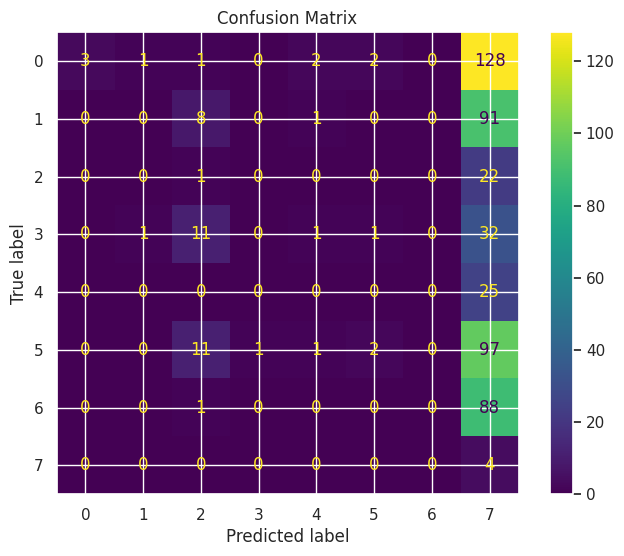

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_adam
------------------------------
TRAIN
Accuracy: 0.7102
Precision: 0.7374
Recall: 0.7102
F1: 0.7060
Kappa: 0.6438
Error Rate: 0.2898

TEST
Accuracy: 0.0149
Precision: 0.3311
Recall: 0.0149
F1: 0.0137
Kappa: 0.0039
Error Rate: 0.9851
Gap (overfitting): 0.6952

CV
Mean: 0.7025
Std: 0.0457
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



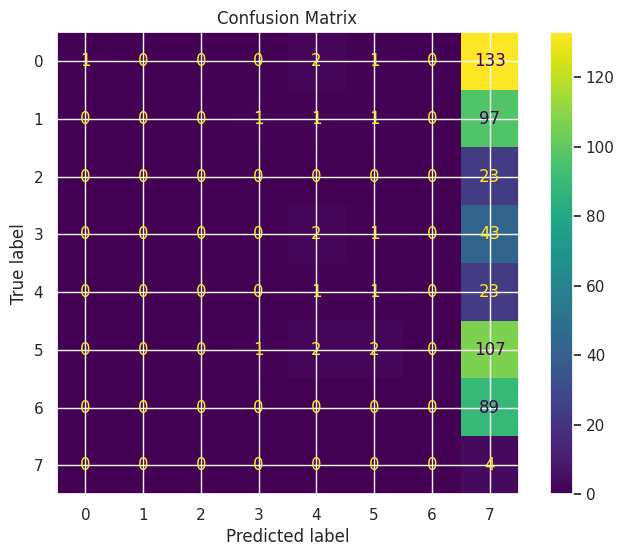

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_sgd_momentum
------------------------------
TRAIN
Accuracy: 0.5508
Precision: 0.5383
Recall: 0.5508
F1: 0.5276
Kappa: 0.4420
Error Rate: 0.4492

TEST
Accuracy: 0.2575
Precision: 0.2411
Recall: 0.2575
F1: 0.1656
Kappa: 0.0820
Error Rate: 0.7425
Gap (overfitting): 0.2934

CV
Mean: 0.5406
Std: 0.0451
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



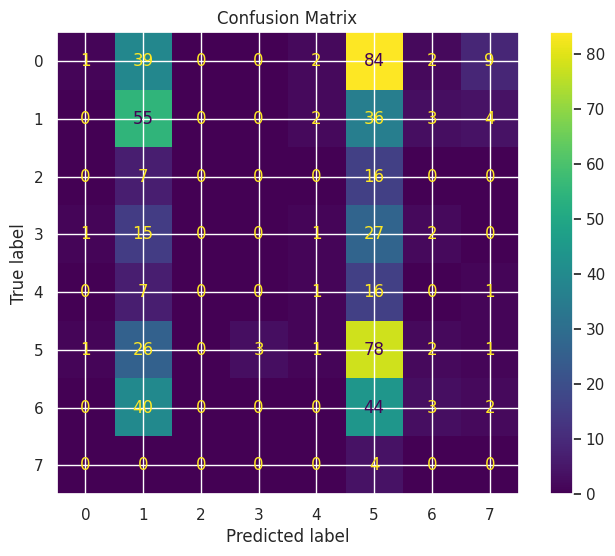

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_adam_lowLR
------------------------------
TRAIN
Accuracy: 0.4980
Precision: 0.5105
Recall: 0.4980
F1: 0.4657
Kappa: 0.3726
Error Rate: 0.5020

TEST
Accuracy: 0.0802
Precision: 0.3244
Recall: 0.0802
F1: 0.0853
Kappa: 0.0224
Error Rate: 0.9198
Gap (overfitting): 0.4178

CV
Mean: 0.5003
Std: 0.0382
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



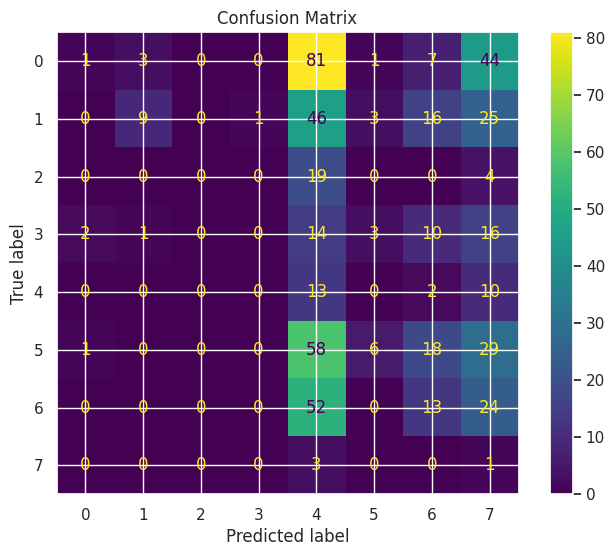

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_relu_adam
------------------------------
TRAIN
Accuracy: 0.5220
Precision: 0.5051
Recall: 0.5220
F1: 0.4942
Kappa: 0.4061
Error Rate: 0.4780

TEST
Accuracy: 0.0187
Precision: 0.1718
Recall: 0.0187
F1: 0.0210
Kappa: 0.0037
Error Rate: 0.9813
Gap (overfitting): 0.5034

CV
Mean: 0.5356
Std: 0.0400
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'relu', 'solver': 'adam', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



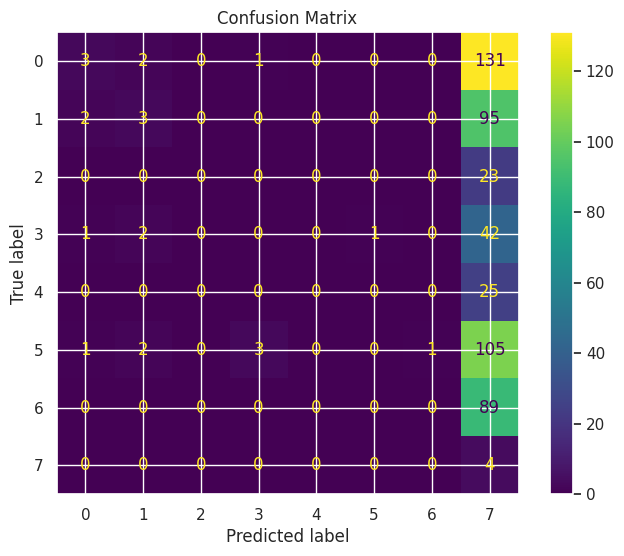

In [6]:
models_rnn = {}


models_rnn['RNN_rmsprop'] = RNNClassifier(
    hidden_size=16, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='rmsprop', learning_rate=0.001,
    epochs=500, batch_size=32, random_state=42
)


models_rnn['RNN_adam'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.001,
    epochs=500, batch_size=32, random_state=42
)


models_rnn['RNN_sgd_momentum'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


models_rnn['RNN_adam_lowLR'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)


# Testar diferentes nonlinearities
models_rnn['RNN_relu_adam'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='relu', solver='adam', learning_rate=0.001,
    epochs=500, batch_size=32, random_state=42
)


main(models_rnn, "rnn_experiments")

/tmp/ipykernel_982/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(res


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_sgd_30
------------------------------
TRAIN
Accuracy: 0.5741
Precision: 0.5719
Recall: 0.5741
F1: 0.5531
Kappa: 0.4691
Error Rate: 0.4259

TEST
Accuracy: 0.1940
Precision: 0.2134
Recall: 0.1940
F1: 0.1361
Kappa: 0.0787
Error Rate: 0.8060
Gap (overfitting): 0.3800

CV
Mean: 0.5507
Std: 0.0183
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



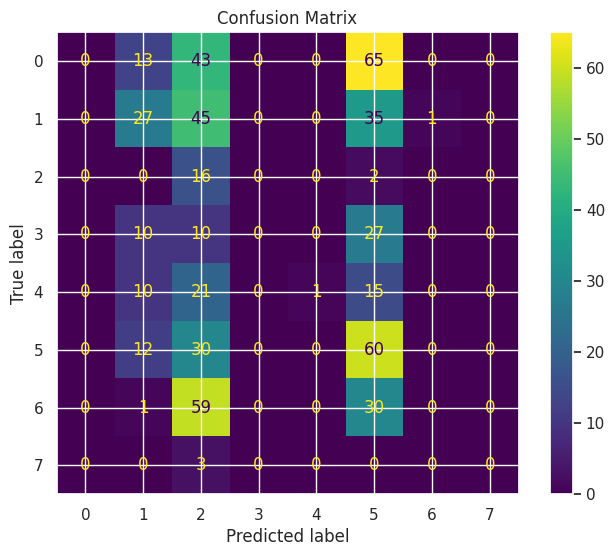

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_sgd_50
------------------------------
TRAIN
Accuracy: 0.5845
Precision: 0.6085
Recall: 0.5845
F1: 0.5725
Kappa: 0.4833
Error Rate: 0.4155

TEST
Accuracy: 0.1978
Precision: 0.1265
Recall: 0.1978
F1: 0.1178
Kappa: 0.0546
Error Rate: 0.8022
Gap (overfitting): 0.3867

CV
Mean: 0.5636
Std: 0.0201
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



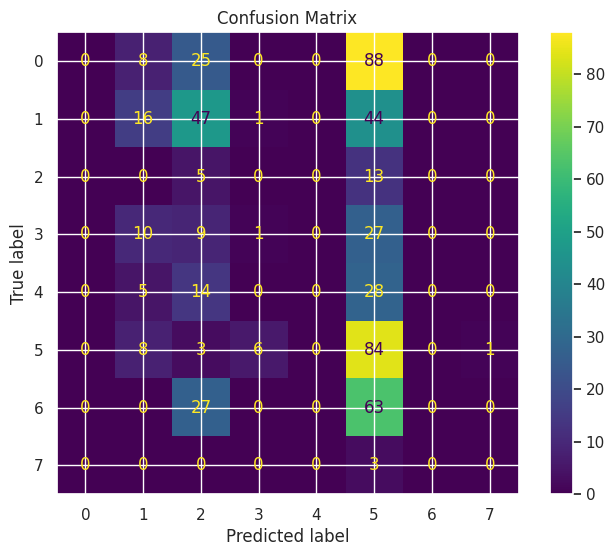

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_sgd_50_25
------------------------------
TRAIN
Accuracy: 0.6661
Precision: 0.6772
Recall: 0.6661
F1: 0.6559
Kappa: 0.5871
Error Rate: 0.3339

TEST
Accuracy: 0.1026
Precision: 0.0774
Recall: 0.1026
F1: 0.0726
Kappa: 0.0117
Error Rate: 0.8974
Gap (overfitting): 0.5635

CV
Mean: 0.6734
Std: 0.0329
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 2, 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



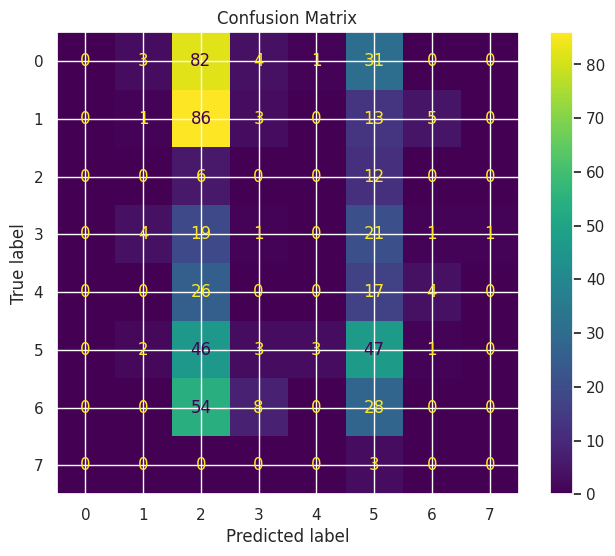

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_sgd_reg1e3
------------------------------
TRAIN
Accuracy: 0.5749
Precision: 0.6078
Recall: 0.5749
F1: 0.5629
Kappa: 0.4711
Error Rate: 0.4251

TEST
Accuracy: 0.1716
Precision: 0.1545
Recall: 0.1716
F1: 0.1296
Kappa: 0.0507
Error Rate: 0.8284
Gap (overfitting): 0.4032

CV
Mean: 0.5473
Std: 0.0136
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 1, 'dropout': 0.3, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



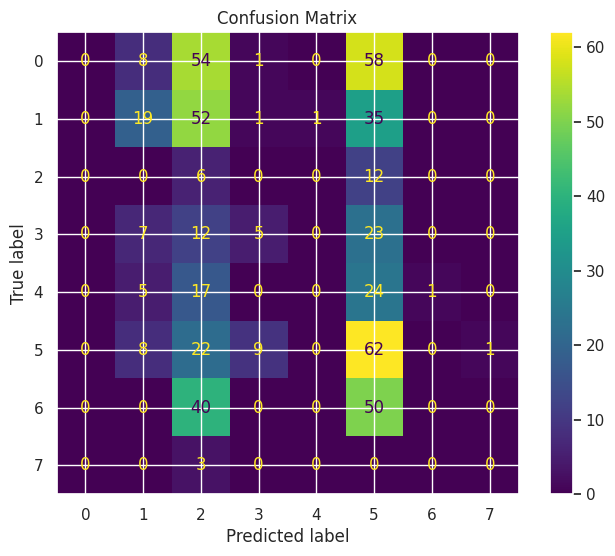

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_sgd_reg5e3
------------------------------
TRAIN
Accuracy: 0.5725
Precision: 0.6121
Recall: 0.5725
F1: 0.5613
Kappa: 0.4675
Error Rate: 0.4275

TEST
Accuracy: 0.1437
Precision: 0.1347
Recall: 0.1437
F1: 0.1131
Kappa: 0.0490
Error Rate: 0.8563
Gap (overfitting): 0.4288

CV
Mean: 0.5406
Std: 0.0150
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 1, 'dropout': 0.5, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



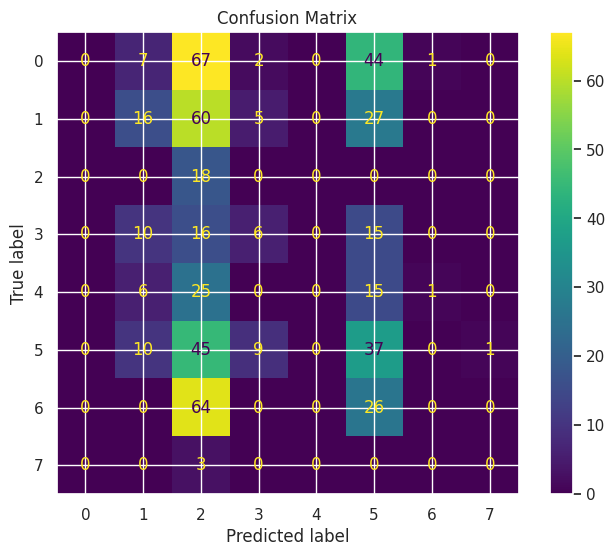

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_rmsprop_30
------------------------------
TRAIN
Accuracy: 0.7158
Precision: 0.7447
Recall: 0.7158
F1: 0.7101
Kappa: 0.6497
Error Rate: 0.2842

TEST
Accuracy: 0.0560
Precision: 0.3117
Recall: 0.0560
F1: 0.0369
Kappa: 0.0093
Error Rate: 0.9440
Gap (overfitting): 0.6598

CV
Mean: 0.7249
Std: 0.0304
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



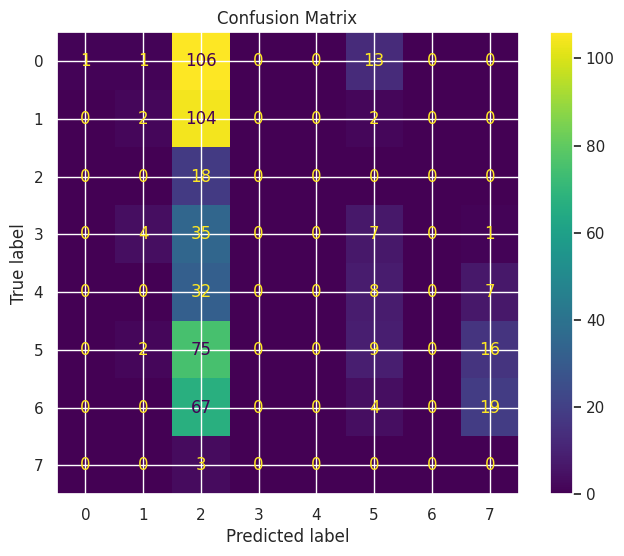

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_rmsprop_50
------------------------------
TRAIN
Accuracy: 0.8102
Precision: 0.8383
Recall: 0.8102
F1: 0.8094
Kappa: 0.7667
Error Rate: 0.1898

TEST
Accuracy: 0.0224
Precision: 0.3949
Recall: 0.0224
F1: 0.0312
Kappa: 0.0120
Error Rate: 0.9776
Gap (overfitting): 0.7879

CV
Mean: 0.8504
Std: 0.0068
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



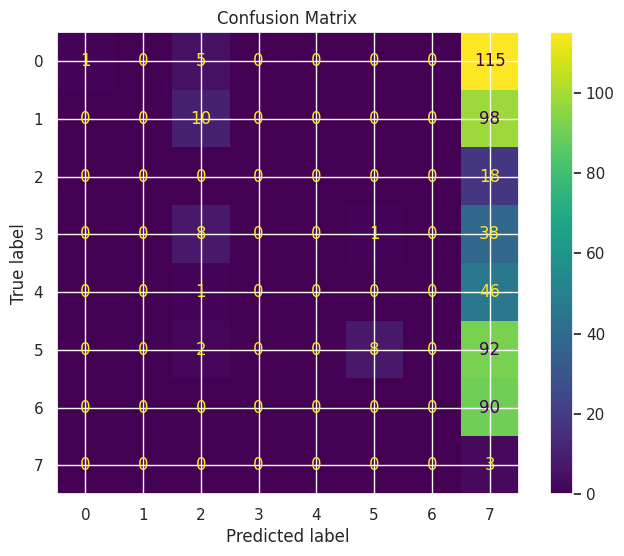

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_rmsprop_50_25
------------------------------
TRAIN
Accuracy: 0.7622
Precision: 0.7700
Recall: 0.7622
F1: 0.7590
Kappa: 0.7117
Error Rate: 0.2378

TEST
Accuracy: 0.0765
Precision: 0.0206
Recall: 0.0765
F1: 0.0219
Kappa: -0.0203
Error Rate: 0.9235
Gap (overfitting): 0.6857

CV
Mean: 0.9675
Std: 0.0273
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 2, 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



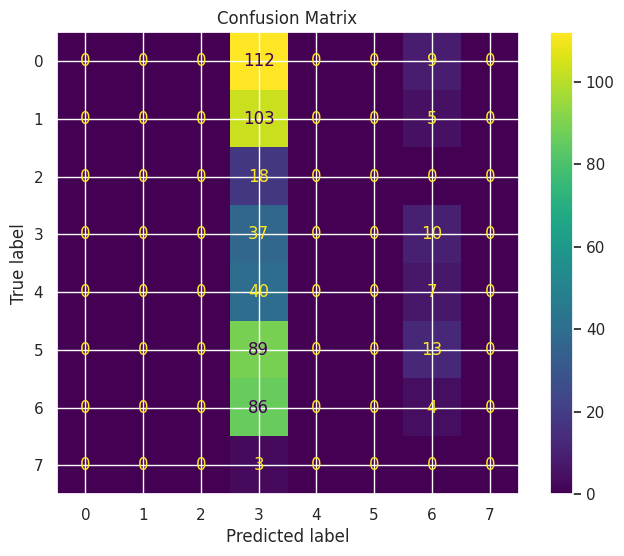

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_rmsprop_reg1e3
------------------------------
TRAIN
Accuracy: 0.6845
Precision: 0.6903
Recall: 0.6845
F1: 0.6832
Kappa: 0.6126
Error Rate: 0.3155

TEST
Accuracy: 0.0280
Precision: 0.0825
Recall: 0.0280
F1: 0.0333
Kappa: 0.0047
Error Rate: 0.9720
Gap (overfitting): 0.6566

CV
Mean: 0.6280
Std: 0.0392
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 1, 'dropout': 0.3, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



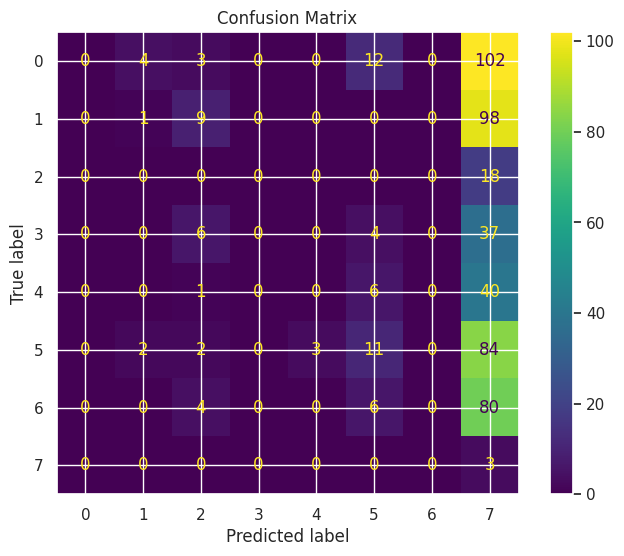

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_adam_lowLR_30
------------------------------
TRAIN
Accuracy: 0.4604
Precision: 0.4055
Recall: 0.4604
F1: 0.4246
Kappa: 0.3286
Error Rate: 0.5396

TEST
Accuracy: 0.0131
Precision: 0.0762
Recall: 0.0131
F1: 0.0137
Kappa: 0.0014
Error Rate: 0.9869
Gap (overfitting): 0.4473

CV
Mean: 0.4689
Std: 0.0091
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



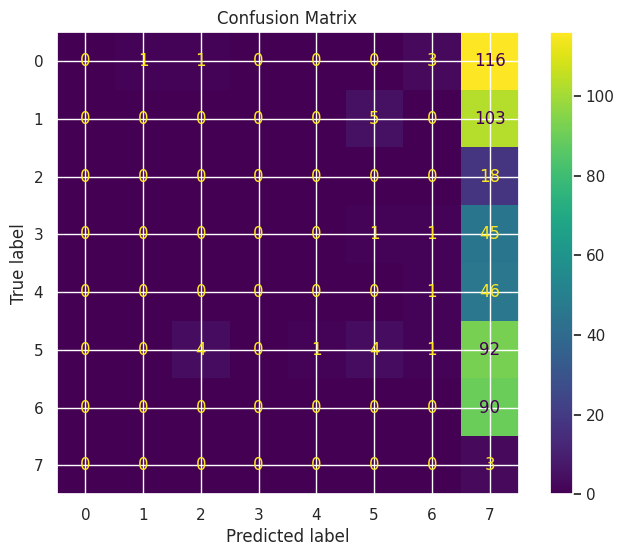

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_adam_lowLR_50
------------------------------
TRAIN
Accuracy: 0.4948
Precision: 0.5311
Recall: 0.4948
F1: 0.4831
Kappa: 0.3728
Error Rate: 0.5052

TEST
Accuracy: 0.0149
Precision: 0.0180
Recall: 0.0149
F1: 0.0043
Kappa: -0.0118
Error Rate: 0.9851
Gap (overfitting): 0.4799

CV
Mean: 0.4868
Std: 0.0102
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



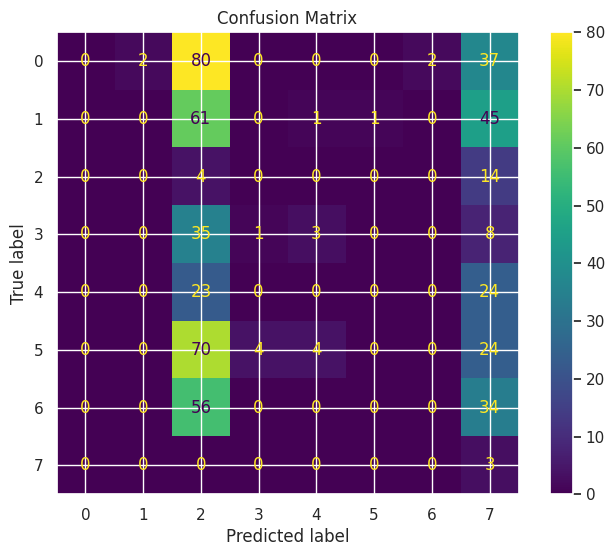

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_adam_lowLR_50_25
------------------------------
TRAIN
Accuracy: 0.5701
Precision: 0.6044
Recall: 0.5701
F1: 0.5567
Kappa: 0.4663
Error Rate: 0.4299

TEST
Accuracy: 0.0709
Precision: 0.0117
Recall: 0.0709
F1: 0.0191
Kappa: -0.0179
Error Rate: 0.9291
Gap (overfitting): 0.4992

CV
Mean: 0.5944
Std: 0.0162
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 2, 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



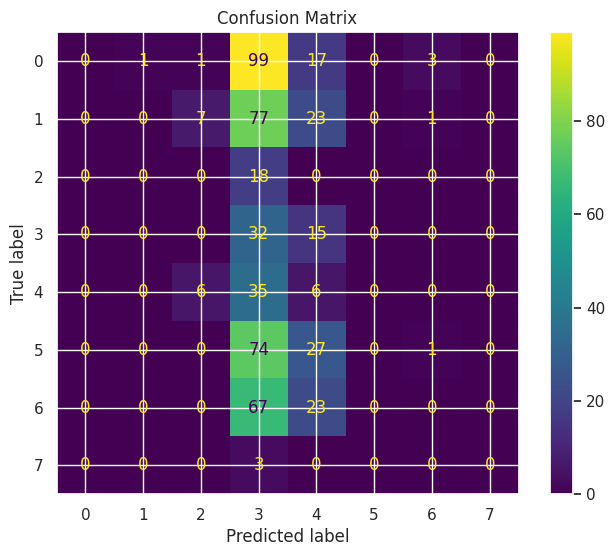

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_adam_lowLR_reg1e3
------------------------------
TRAIN
Accuracy: 0.4660
Precision: 0.5062
Recall: 0.4660
F1: 0.4539
Kappa: 0.3365
Error Rate: 0.5340

TEST
Accuracy: 0.0075
Precision: 0.0176
Recall: 0.0075
F1: 0.0034
Kappa: -0.0034
Error Rate: 0.9925
Gap (overfitting): 0.4585

CV
Mean: 0.4829
Std: 0.0136
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 1, 'dropout': 0.3, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



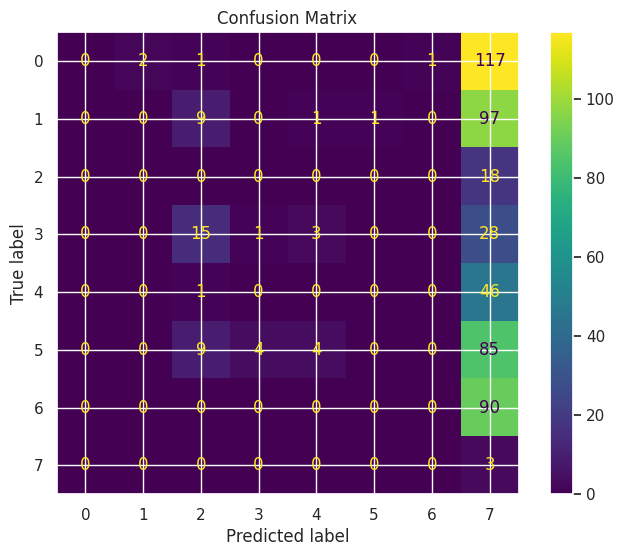

In [6]:
models_rnn_f1 = {}


# ============================================================
# 1º MELHOR: RNN_sgd_momentum
# ============================================================


models_rnn_f1['RNN_sgd_30'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f1['RNN_sgd_50'] = RNNClassifier(
    hidden_size=16, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


# 2 camadas RNN + FC
models_rnn_f1['RNN_sgd_50_25'] = RNNClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


# Regularização (dropout)
models_rnn_f1['RNN_sgd_reg1e3'] = RNNClassifier(
    hidden_size=16, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f1['RNN_sgd_reg5e3'] = RNNClassifier(
    hidden_size=16, num_layers=1, dropout=0.5, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 2º MELHOR: RNN_rmsprop
# ============================================================


models_rnn_f1['RNN_rmsprop_30'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='rmsprop', learning_rate=0.001,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f1['RNN_rmsprop_50'] = RNNClassifier(
    hidden_size=16, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='rmsprop', learning_rate=0.001,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f1['RNN_rmsprop_50_25'] = RNNClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    nonlinearity='tanh', solver='rmsprop', learning_rate=0.001,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f1['RNN_rmsprop_reg1e3'] = RNNClassifier(
    hidden_size=16, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    nonlinearity='tanh', solver='rmsprop', learning_rate=0.001,
    epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 3º MELHOR: RNN_adam_lowLR
# ============================================================


models_rnn_f1['RNN_adam_lowLR_30'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f1['RNN_adam_lowLR_50'] = RNNClassifier(
    hidden_size=16, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f1['RNN_adam_lowLR_50_25'] = RNNClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f1['RNN_adam_lowLR_reg1e3'] = RNNClassifier(
    hidden_size=16, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)


main(models_rnn_f1, "rnn_fase_1")




/tmp/ipykernel_982/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(res


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_1
------------------------------
TRAIN
Accuracy: 0.4564
Precision: 0.4922
Recall: 0.4564
F1: 0.4310
Kappa: 0.3228
Error Rate: 0.5436

TEST
Accuracy: 0.0560
Precision: 0.1947
Recall: 0.0560
F1: 0.0549
Kappa: 0.0110
Error Rate: 0.9440
Gap (overfitting): 0.4004

CV
Mean: 0.4779
Std: 0.0101
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



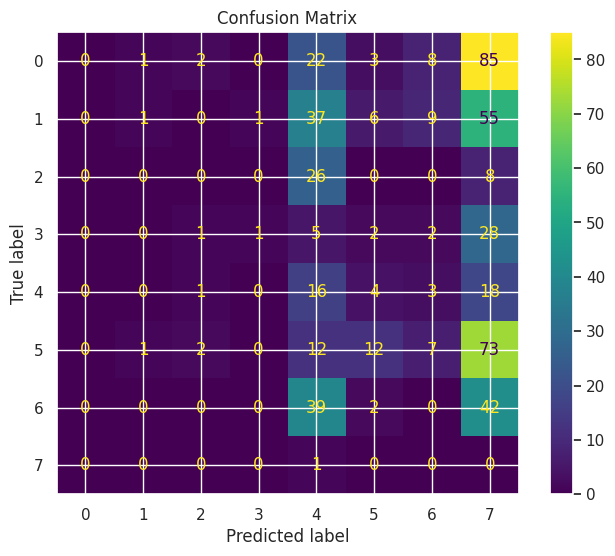

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_2
------------------------------
TRAIN
Accuracy: 0.5140
Precision: 0.5178
Recall: 0.5140
F1: 0.4850
Kappa: 0.3966
Error Rate: 0.4860

TEST
Accuracy: 0.1437
Precision: 0.2965
Recall: 0.1437
F1: 0.1082
Kappa: 0.0302
Error Rate: 0.8563
Gap (overfitting): 0.3704

CV
Mean: 0.4975
Std: 0.0175
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 320, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



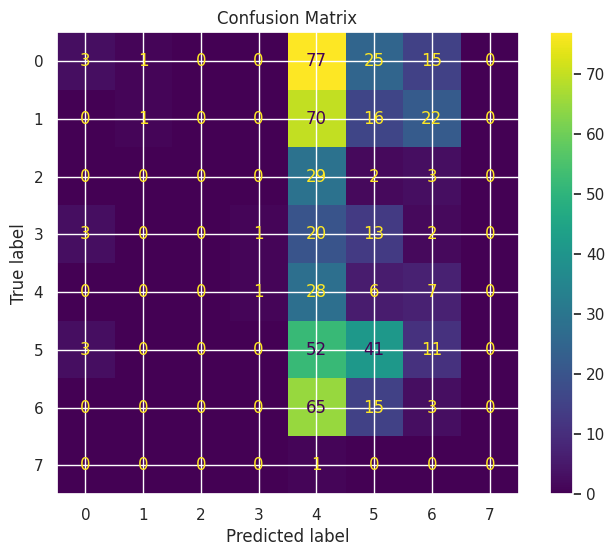

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_3
------------------------------
TRAIN
Accuracy: 0.6429
Precision: 0.6914
Recall: 0.6429
F1: 0.6376
Kappa: 0.5596
Error Rate: 0.3571

TEST
Accuracy: 0.0037
Precision: 0.0665
Recall: 0.0037
F1: 0.0036
Kappa: 0.0006
Error Rate: 0.9963
Gap (overfitting): 0.6392

CV
Mean: 0.6409
Std: 0.0230
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



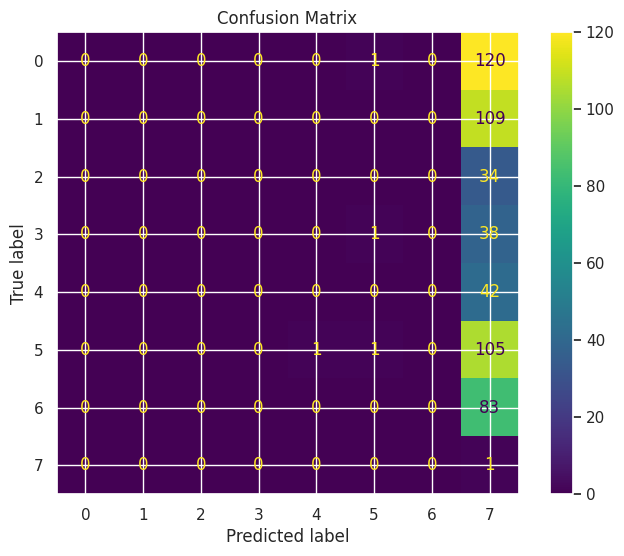

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_4
------------------------------
TRAIN
Accuracy: 0.4564
Precision: 0.4922
Recall: 0.4564
F1: 0.4310
Kappa: 0.3228
Error Rate: 0.5436

TEST
Accuracy: 0.0560
Precision: 0.1947
Recall: 0.0560
F1: 0.0549
Kappa: 0.0110
Error Rate: 0.9440
Gap (overfitting): 0.4004

CV
Mean: 0.4779
Std: 0.0101
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



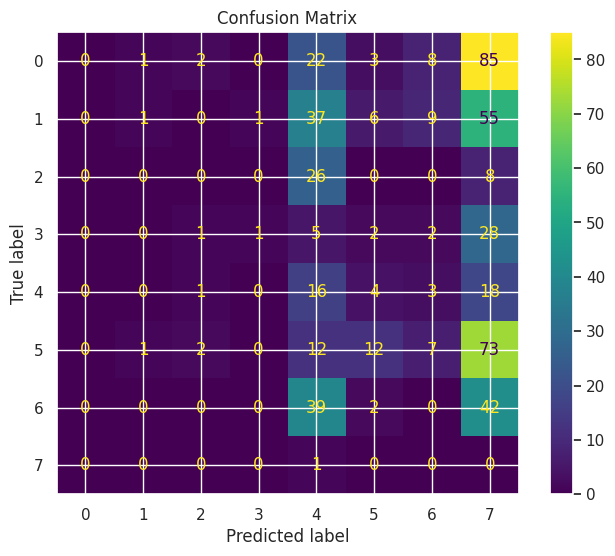

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_5
------------------------------
TRAIN
Accuracy: 0.4780
Precision: 0.5050
Recall: 0.4780
F1: 0.4570
Kappa: 0.3521
Error Rate: 0.5220

TEST
Accuracy: 0.0075
Precision: 0.0494
Recall: 0.0075
F1: 0.0096
Kappa: -0.0056
Error Rate: 0.9925
Gap (overfitting): 0.4705

CV
Mean: 0.5076
Std: 0.0208
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



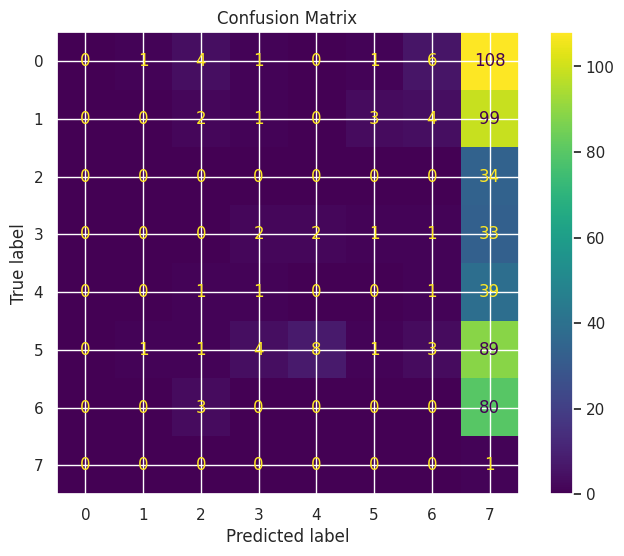

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_6
------------------------------
TRAIN
Accuracy: 0.5749
Precision: 0.6334
Recall: 0.5749
F1: 0.5520
Kappa: 0.4727
Error Rate: 0.4251

TEST
Accuracy: 0.1884
Precision: 0.1185
Recall: 0.1884
F1: 0.0986
Kappa: 0.0511
Error Rate: 0.8116
Gap (overfitting): 0.3864

CV
Mean: 0.6095
Std: 0.0310
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 2, 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



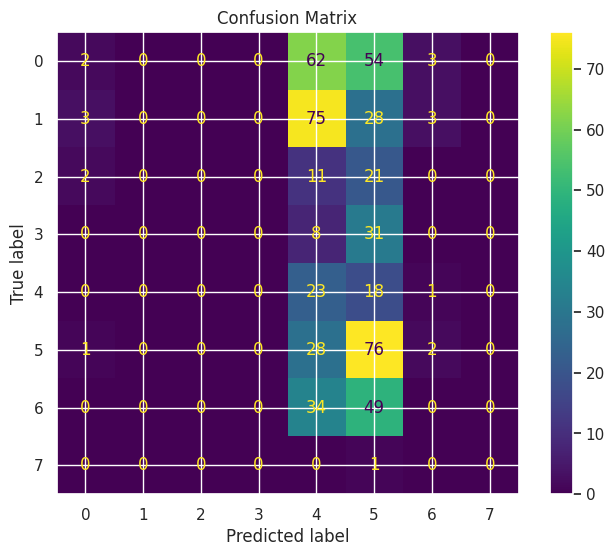

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN7
------------------------------
TRAIN
Accuracy: 0.4564
Precision: 0.4922
Recall: 0.4564
F1: 0.4310
Kappa: 0.3228
Error Rate: 0.5436

TEST
Accuracy: 0.0560
Precision: 0.1947
Recall: 0.0560
F1: 0.0549
Kappa: 0.0110
Error Rate: 0.9440
Gap (overfitting): 0.4004

CV
Mean: 0.4779
Std: 0.0101
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



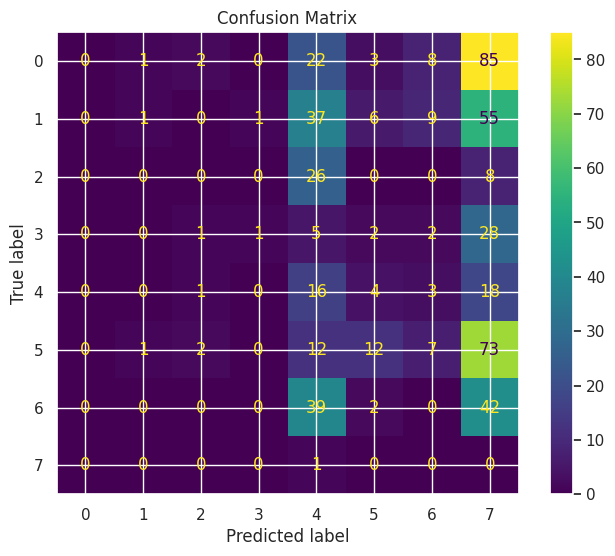

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN8
------------------------------
TRAIN
Accuracy: 0.4636
Precision: 0.5039
Recall: 0.4636
F1: 0.4365
Kappa: 0.3317
Error Rate: 0.5364

TEST
Accuracy: 0.0597
Precision: 0.1972
Recall: 0.0597
F1: 0.0599
Kappa: 0.0158
Error Rate: 0.9403
Gap (overfitting): 0.4039

CV
Mean: 0.4745
Std: 0.0090
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.1, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



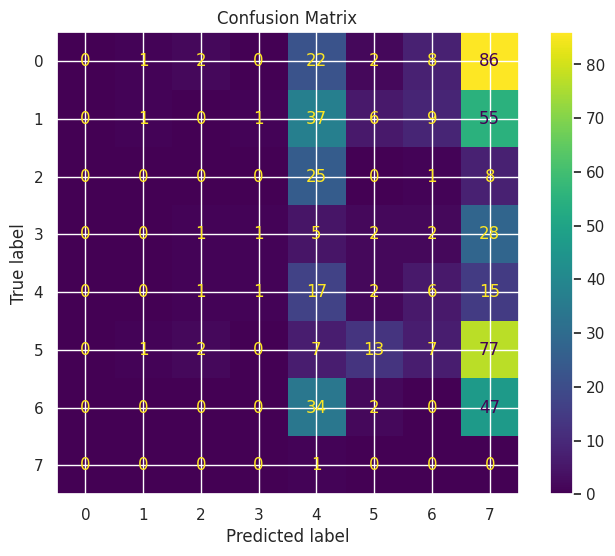

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_9
------------------------------
TRAIN
Accuracy: 0.4684
Precision: 0.5192
Recall: 0.4684
F1: 0.4411
Kappa: 0.3368
Error Rate: 0.5316

TEST
Accuracy: 0.0392
Precision: 0.1463
Recall: 0.0392
F1: 0.0490
Kappa: -0.0037
Error Rate: 0.9608
Gap (overfitting): 0.4292

CV
Mean: 0.4695
Std: 0.0136
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



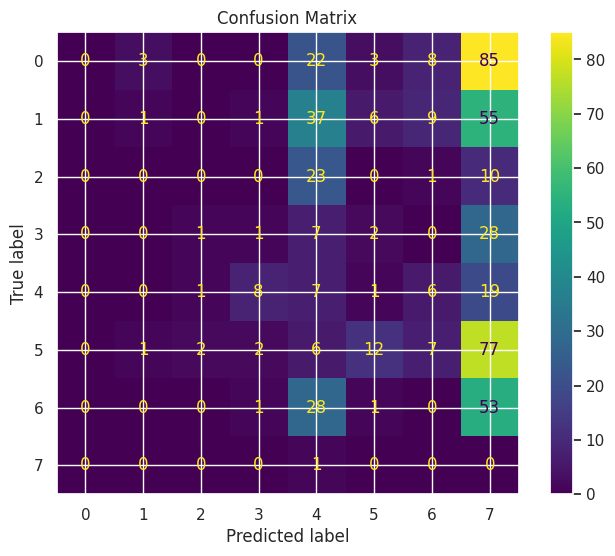

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_10
------------------------------
TRAIN
Accuracy: 0.4684
Precision: 0.5233
Recall: 0.4684
F1: 0.4405
Kappa: 0.3360
Error Rate: 0.5316

TEST
Accuracy: 0.0522
Precision: 0.1452
Recall: 0.0522
F1: 0.0583
Kappa: 0.0037
Error Rate: 0.9478
Gap (overfitting): 0.4161

CV
Mean: 0.4678
Std: 0.0094
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.3, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



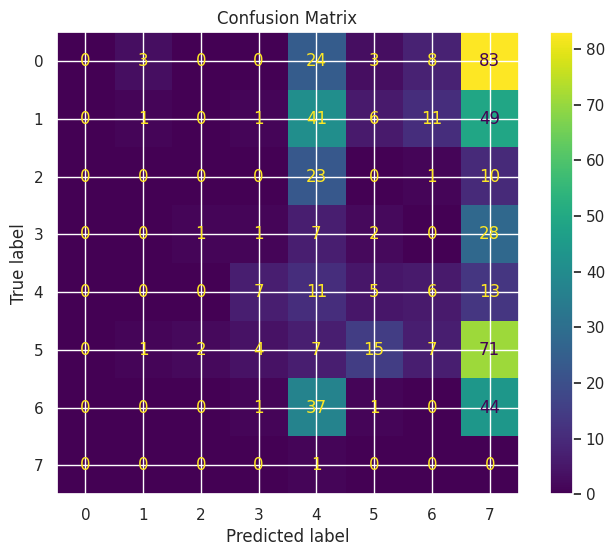

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_11
------------------------------
TRAIN
Accuracy: 0.4564
Precision: 0.4922
Recall: 0.4564
F1: 0.4310
Kappa: 0.3228
Error Rate: 0.5436

TEST
Accuracy: 0.0560
Precision: 0.1947
Recall: 0.0560
F1: 0.0549
Kappa: 0.0110
Error Rate: 0.9440
Gap (overfitting): 0.4004

CV
Mean: 0.4779
Std: 0.0101
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



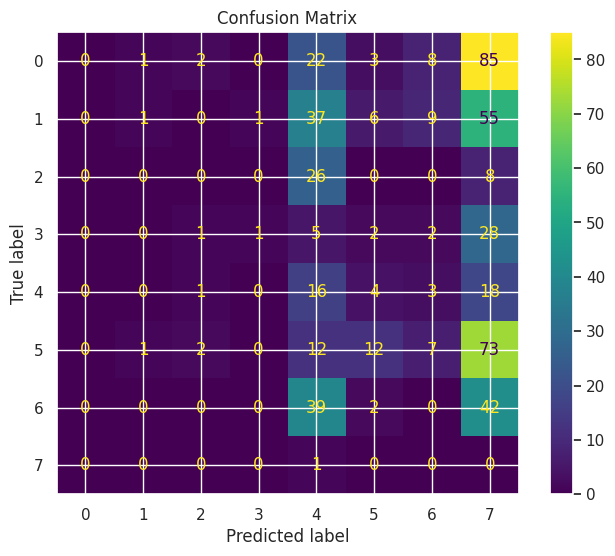

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_12
------------------------------
TRAIN
Accuracy: 0.4315
Precision: 0.5186
Recall: 0.4315
F1: 0.3997
Kappa: 0.2841
Error Rate: 0.5685

TEST
Accuracy: 0.0765
Precision: 0.0978
Recall: 0.0765
F1: 0.0242
Kappa: -0.0077
Error Rate: 0.9235
Gap (overfitting): 0.3551

CV
Mean: 0.4224
Std: 0.0268
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'relu', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



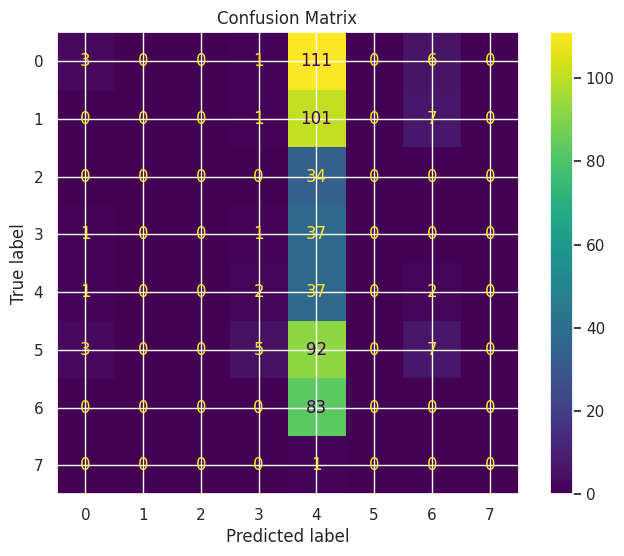

In [7]:
models_rnn_f2 = {}




# ============================================================
# OTIMIZADORES
# ============================================================




models_rnn_f2['RNN_1'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f2['RNN_2'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=320, batch_size=32, random_state=42
)




models_rnn_f2['RNN_3'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='rmsprop', learning_rate=0.001,
    epochs=500, batch_size=32, random_state=42
)




# ============================================================
# ARQUITETURAS
# ============================================================








# hidden_size = 30
models_rnn_f2['RNN_4'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)




# hidden_size = 50
models_rnn_f2['RNN_5'] = RNNClassifier(
    hidden_size=16, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)




# 2 camadas RNN + FC (50_25)
models_rnn_f2['RNN_6'] = RNNClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)




# ============================================================
# REGULARIZAÇÃO
# ============================================================




models_rnn_f2['RNN7'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f2['RNN8'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.1, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f2['RNN_9'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f2['RNN_10'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)




# ============================================================
# NONLINEARITY (equivalente a ativação)
# ============================================================




models_rnn_f2['RNN_11'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f2['RNN_12'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='relu', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)




main(models_rnn_f2, "rnn_fase_2")

/tmp/ipykernel_982/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(res


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_1
------------------------------
TRAIN
Accuracy: 0.5068
Precision: 0.4931
Recall: 0.5068
F1: 0.4862
Kappa: 0.3870
Error Rate: 0.4932

TEST
Accuracy: 0.2743
Precision: 0.2228
Recall: 0.2743
F1: 0.1848
Kappa: 0.0802
Error Rate: 0.7257
Gap (overfitting): 0.2326

CV
Mean: 0.4723
Std: 0.0268
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



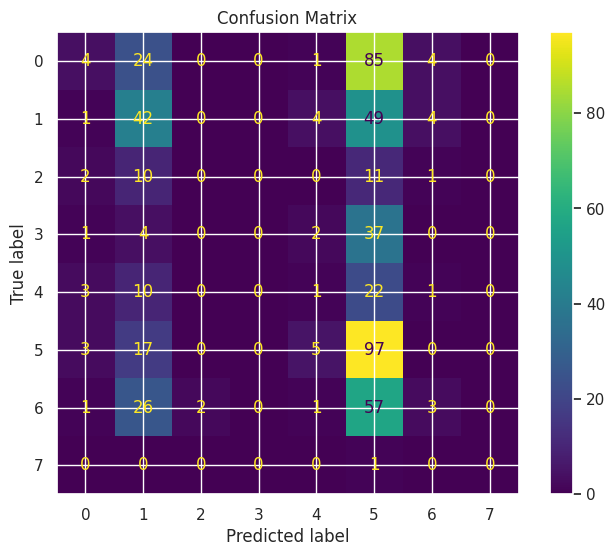

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_2
------------------------------
TRAIN
Accuracy: 0.5572
Precision: 0.5765
Recall: 0.5572
F1: 0.5506
Kappa: 0.4527
Error Rate: 0.4428

TEST
Accuracy: 0.2743
Precision: 0.2098
Recall: 0.2743
F1: 0.1888
Kappa: 0.0911
Error Rate: 0.7257
Gap (overfitting): 0.2830

CV
Mean: 0.5401
Std: 0.0298
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



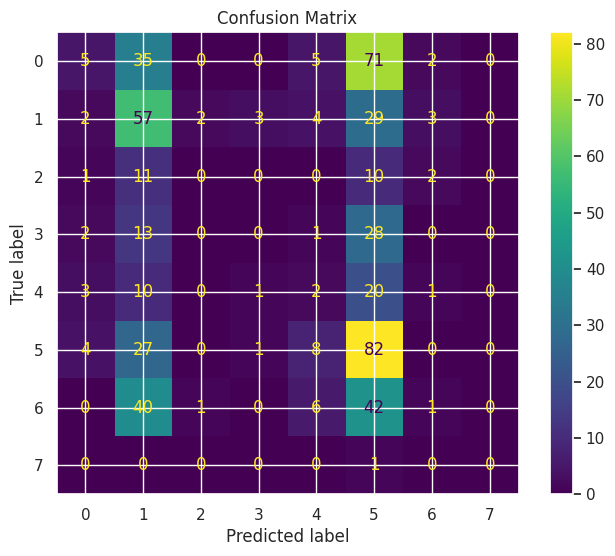

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_3
------------------------------
TRAIN
Accuracy: 0.5252
Precision: 0.5433
Recall: 0.5252
F1: 0.5106
Kappa: 0.4116
Error Rate: 0.4748

TEST
Accuracy: 0.2201
Precision: 0.1466
Recall: 0.2201
F1: 0.1623
Kappa: 0.0457
Error Rate: 0.7799
Gap (overfitting): 0.3051

CV
Mean: 0.4896
Std: 0.0197
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



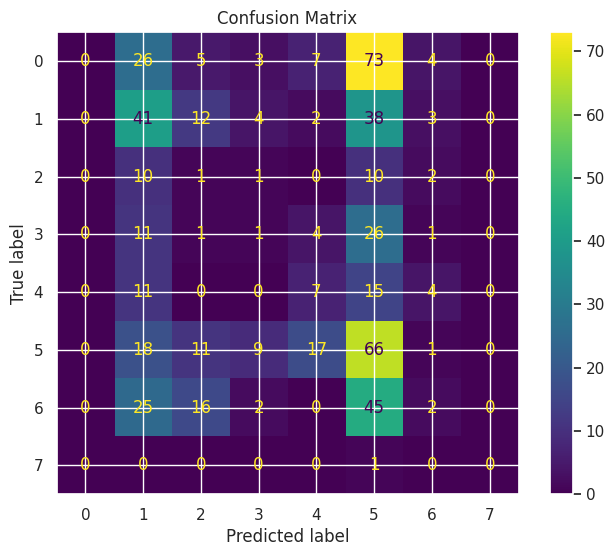

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_4
------------------------------
TRAIN
Accuracy: 0.5885
Precision: 0.6154
Recall: 0.5885
F1: 0.5838
Kappa: 0.4909
Error Rate: 0.4115

TEST
Accuracy: 0.1716
Precision: 0.1147
Recall: 0.1716
F1: 0.1331
Kappa: 0.0245
Error Rate: 0.8284
Gap (overfitting): 0.4168

CV
Mean: 0.5653
Std: 0.0451
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



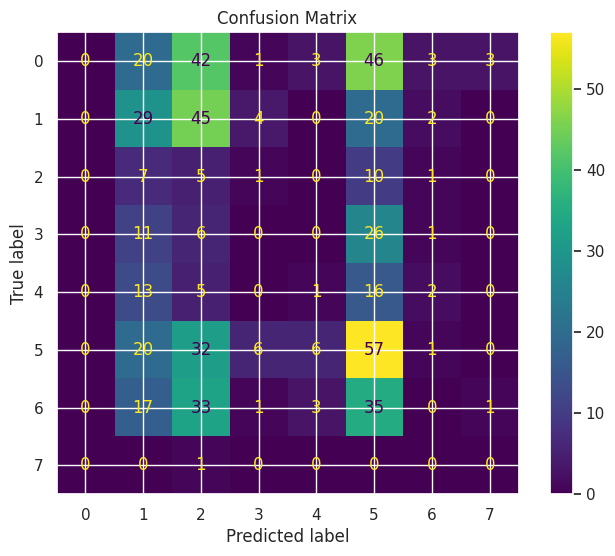

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_5
------------------------------
TRAIN
Accuracy: 0.5276
Precision: 0.5135
Recall: 0.5276
F1: 0.5069
Kappa: 0.4138
Error Rate: 0.4724

TEST
Accuracy: 0.2425
Precision: 0.1706
Recall: 0.2425
F1: 0.1854
Kappa: 0.0717
Error Rate: 0.7575
Gap (overfitting): 0.2851

CV
Mean: 0.5350
Std: 0.0274
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 2, 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



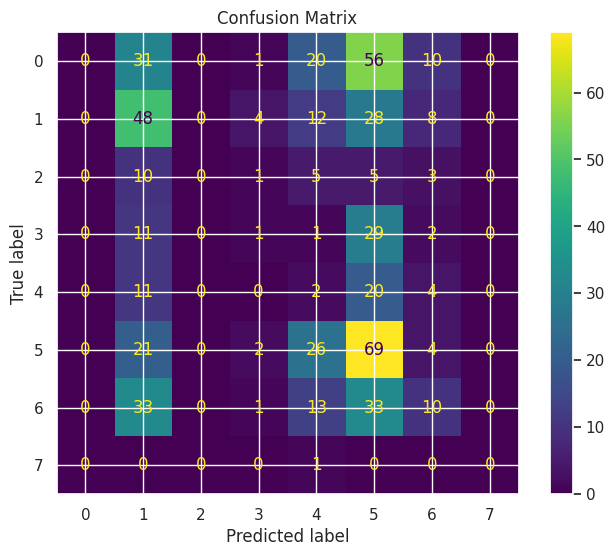

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_6
------------------------------
TRAIN
Accuracy: 0.7614
Precision: 0.7809
Recall: 0.7614
F1: 0.7558
Kappa: 0.7059
Error Rate: 0.2386

TEST
Accuracy: 0.2146
Precision: 0.1995
Recall: 0.2146
F1: 0.1317
Kappa: 0.0346
Error Rate: 0.7854
Gap (overfitting): 0.5469

CV
Mean: 0.7367
Std: 0.0763
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 2, 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



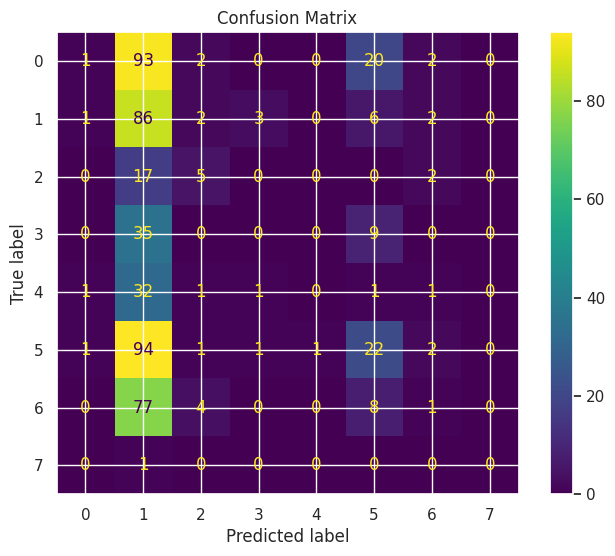

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_7
------------------------------
TRAIN
Accuracy: 0.4091
Precision: 0.3839
Recall: 0.4091
F1: 0.3563
Kappa: 0.2582
Error Rate: 0.5909

TEST
Accuracy: 0.2351
Precision: 0.2408
Recall: 0.2351
F1: 0.1931
Kappa: 0.0661
Error Rate: 0.7649
Gap (overfitting): 0.1741

CV
Mean: 0.4118
Std: 0.0358
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



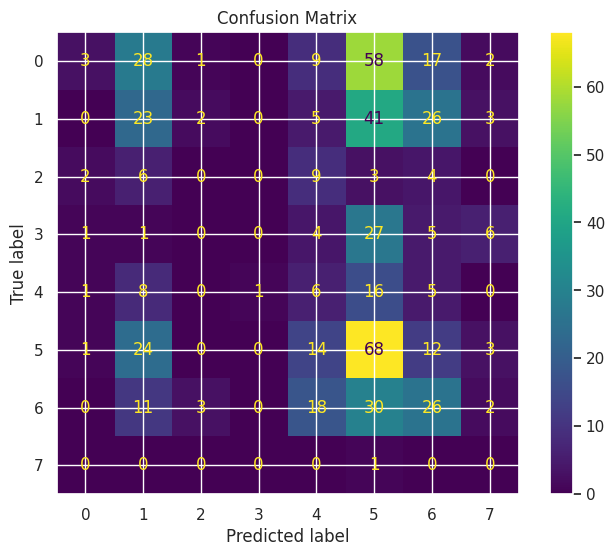

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_8
------------------------------
TRAIN
Accuracy: 0.4716
Precision: 0.5074
Recall: 0.4716
F1: 0.4601
Kappa: 0.3425
Error Rate: 0.5284

TEST
Accuracy: 0.1250
Precision: 0.3768
Recall: 0.1250
F1: 0.1259
Kappa: 0.0453
Error Rate: 0.8750
Gap (overfitting): 0.3466

CV
Mean: 0.4672
Std: 0.0234
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 1, 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



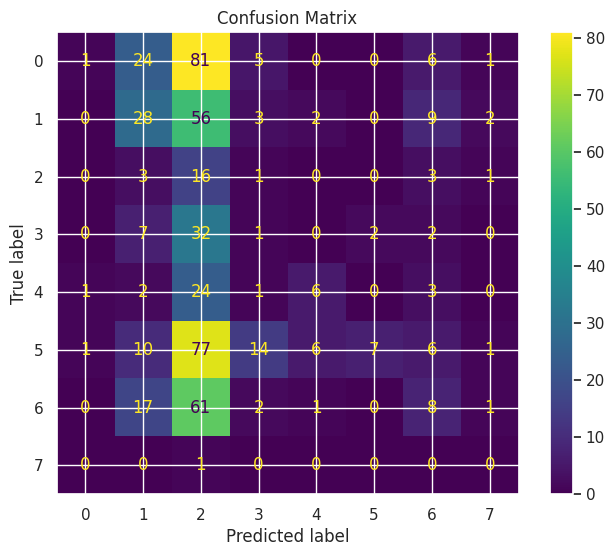

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_9
------------------------------
TRAIN
Accuracy: 0.4980
Precision: 0.5292
Recall: 0.4980
F1: 0.4695
Kappa: 0.3744
Error Rate: 0.5020

TEST
Accuracy: 0.1437
Precision: 0.2023
Recall: 0.1437
F1: 0.1066
Kappa: 0.0425
Error Rate: 0.8563
Gap (overfitting): 0.3543

CV
Mean: 0.5048
Std: 0.0226
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 2, 'dropout': 0.2, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



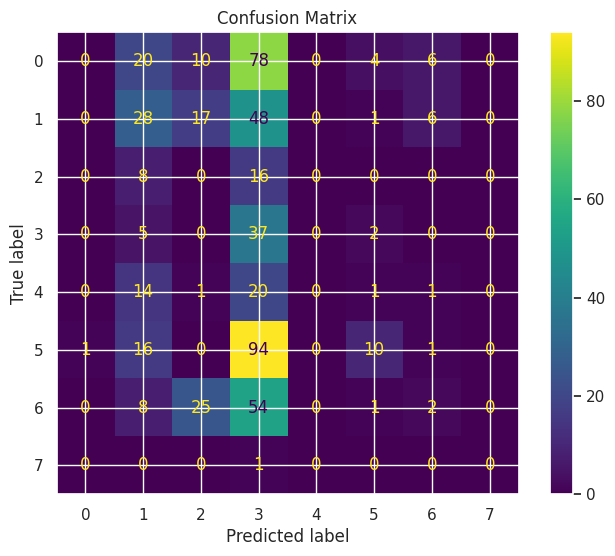

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_10
------------------------------
TRAIN
Accuracy: 0.5140
Precision: 0.5011
Recall: 0.5140
F1: 0.4877
Kappa: 0.3947
Error Rate: 0.4860

TEST
Accuracy: 0.2668
Precision: 0.1859
Recall: 0.2668
F1: 0.1679
Kappa: 0.0657
Error Rate: 0.7332
Gap (overfitting): 0.2472

CV
Mean: 0.4768
Std: 0.0150
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



In [ ]:
models_rnn_f3 = {}




# ============================================================
# 🔥 BASE TOP (SGD)
# ============================================================




models_rnn_f3['F2_1'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f3['F2_2'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.95,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f3['F2_3'] = RNNClassifier(
    hidden_size=16, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f3['F2_4'] = RNNClassifier(
    hidden_size=16, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.95,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f3['F2_5'] = RNNClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f3['F2_6'] = RNNClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.95,
    epochs=500, batch_size=32, random_state=42
)




# ============================================================
# ⚖️ CONTROLE (ADAM)
# ============================================================




models_rnn_f3['F2_7'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f3['F2_8'] = RNNClassifier(
    hidden_size=16, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f3['F2_9'] = RNNClassifier(
    hidden_size=16, num_layers=2, dropout=0.2, fc_hidden_layers=(25,),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)




# ============================================================
# 🔥 EXTRA: Regularização para SGD
# ============================================================




models_rnn_f3['F2_10'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f3['F2_11'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)




models_rnn_f3['F2_12'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.0001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)




main(models_rnn_f3, "rnn_fase_3")

/tmp/ipykernel_1199/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_1
------------------------------
TRAIN
Accuracy: 0.5588
Precision: 0.5650
Recall: 0.5588
F1: 0.5486
Kappa: 0.4568
Error Rate: 0.4412

TEST
Accuracy: 0.2743
Precision: 0.4968
Recall: 0.2743
F1: 0.2294
Kappa: 0.1278
Error Rate: 0.7257
Gap (overfitting): 0.2846

CV
Mean: 0.5731
Std: 0.0206
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



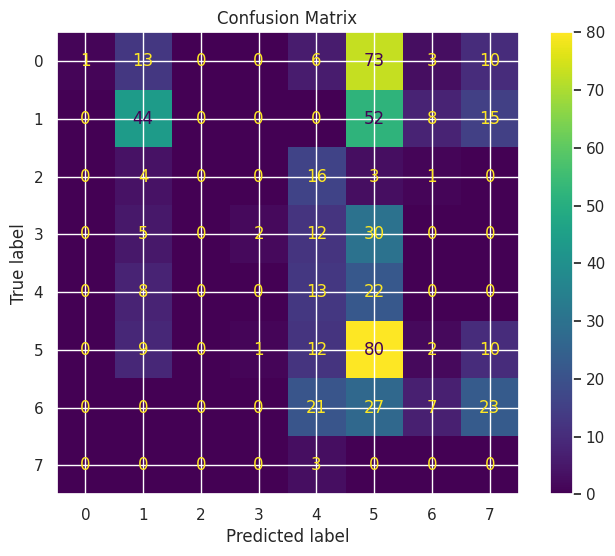

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_2
------------------------------
TRAIN
Accuracy: 0.4980
Precision: 0.4921
Recall: 0.4980
F1: 0.4787
Kappa: 0.3806
Error Rate: 0.5020

TEST
Accuracy: 0.1810
Precision: 0.3397
Recall: 0.1810
F1: 0.1417
Kappa: 0.0745
Error Rate: 0.8190
Gap (overfitting): 0.3170

CV
Mean: 0.5193
Std: 0.0177
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



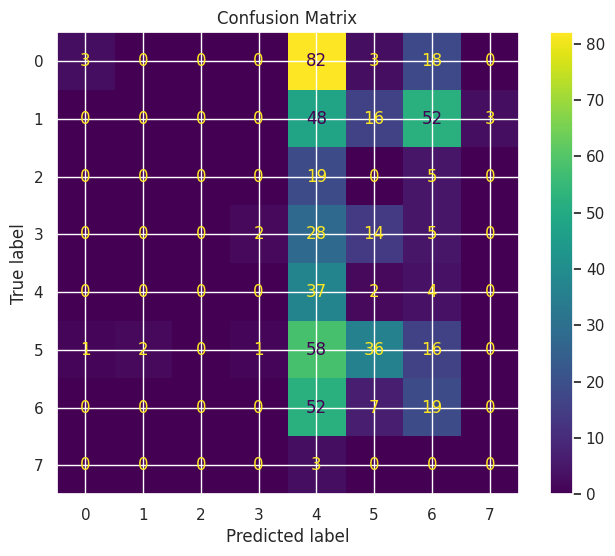

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_3
------------------------------
TRAIN
Accuracy: 0.2834
Precision: 0.1385
Recall: 0.2834
F1: 0.1735
Kappa: 0.0799
Error Rate: 0.7166

TEST
Accuracy: 0.2108
Precision: 0.1912
Recall: 0.2108
F1: 0.0904
Kappa: -0.0016
Error Rate: 0.7892
Gap (overfitting): 0.0726

CV
Mean: 0.2924
Std: 0.0239
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



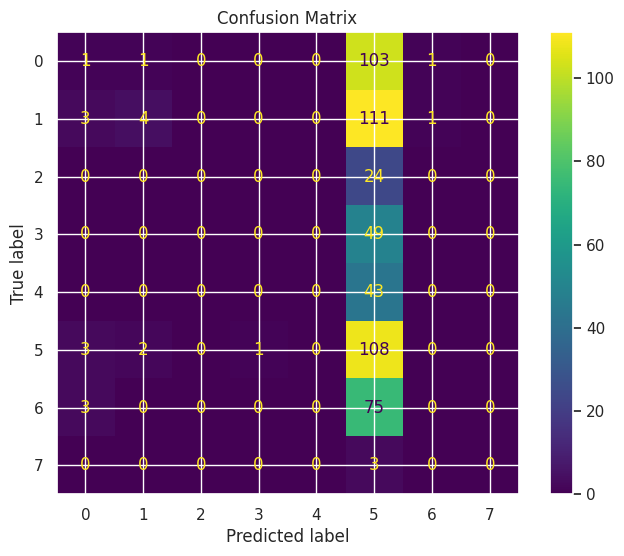

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_4
------------------------------
TRAIN
Accuracy: 0.5556
Precision: 0.5526
Recall: 0.5556
F1: 0.5446
Kappa: 0.4534
Error Rate: 0.4444

TEST
Accuracy: 0.2612
Precision: 0.2469
Recall: 0.2612
F1: 0.2034
Kappa: 0.1031
Error Rate: 0.7388
Gap (overfitting): 0.2945

CV
Mean: 0.5675
Std: 0.0143
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.1, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



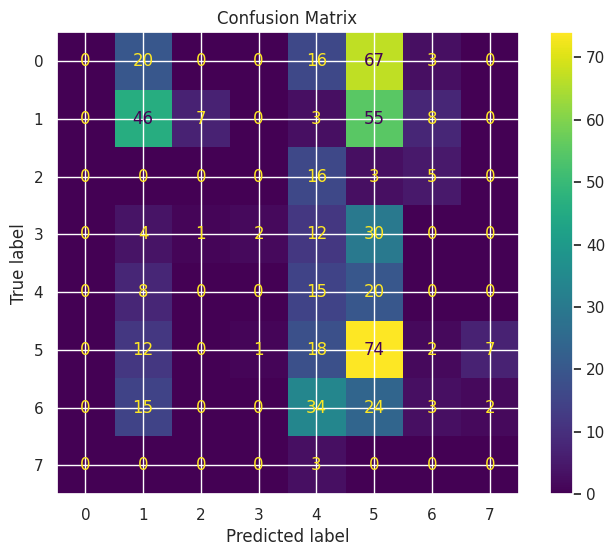

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_5
------------------------------
TRAIN
Accuracy: 0.5380
Precision: 0.5343
Recall: 0.5380
F1: 0.5257
Kappa: 0.4315
Error Rate: 0.4620

TEST
Accuracy: 0.2388
Precision: 0.2510
Recall: 0.2388
F1: 0.2014
Kappa: 0.0991
Error Rate: 0.7612
Gap (overfitting): 0.2992

CV
Mean: 0.5619
Std: 0.0090
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



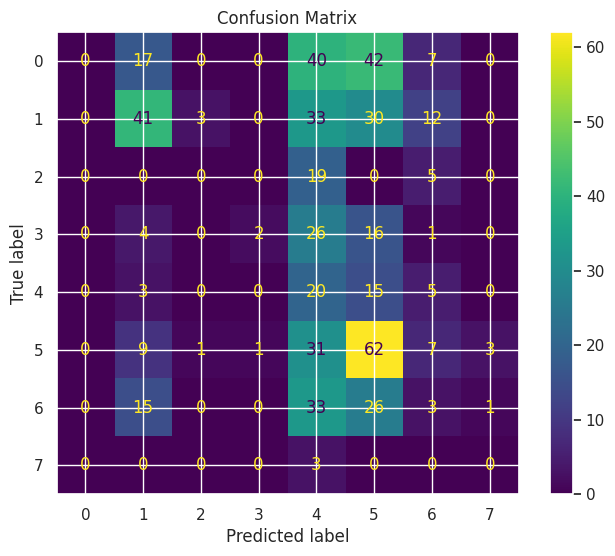

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_6
------------------------------
TRAIN
Accuracy: 0.5268
Precision: 0.5267
Recall: 0.5268
F1: 0.5146
Kappa: 0.4168
Error Rate: 0.4732

TEST
Accuracy: 0.1884
Precision: 0.2520
Recall: 0.1884
F1: 0.1711
Kappa: 0.0753
Error Rate: 0.8116
Gap (overfitting): 0.3384

CV
Mean: 0.5479
Std: 0.0082
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.3, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



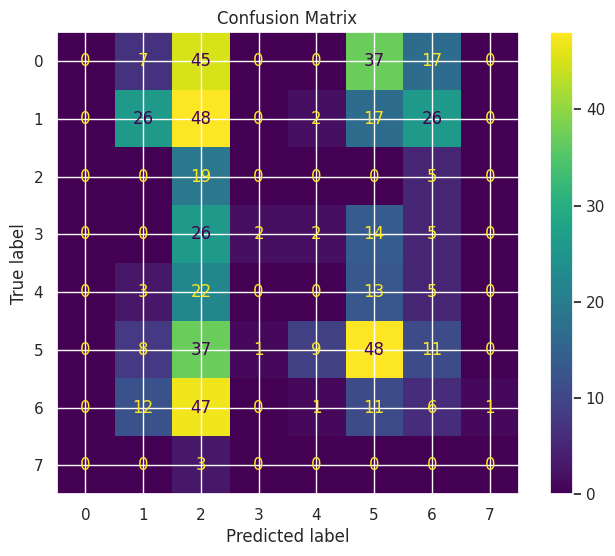

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_7
------------------------------
TRAIN
Accuracy: 0.4940
Precision: 0.4878
Recall: 0.4940
F1: 0.4726
Kappa: 0.3765
Error Rate: 0.5060

TEST
Accuracy: 0.1418
Precision: 0.2018
Recall: 0.1418
F1: 0.1001
Kappa: 0.0433
Error Rate: 0.8582
Gap (overfitting): 0.3522

CV
Mean: 0.5048
Std: 0.0129
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



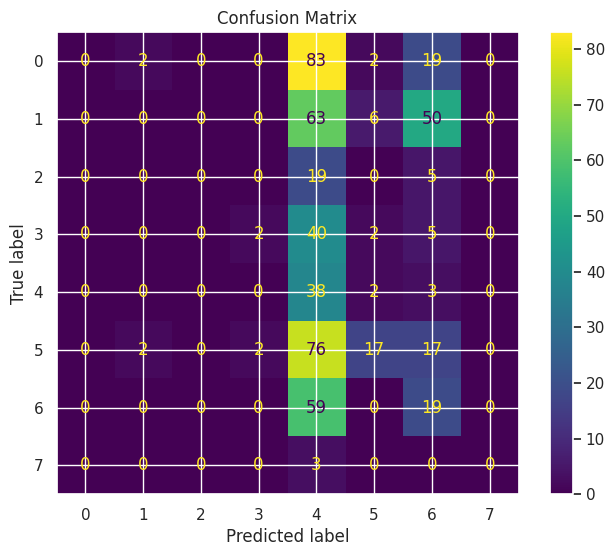

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_8
------------------------------
TRAIN
Accuracy: 0.6637
Precision: 0.7084
Recall: 0.6637
F1: 0.6637
Kappa: 0.5876
Error Rate: 0.3363

TEST
Accuracy: 0.1791
Precision: 0.0937
Recall: 0.1791
F1: 0.1108
Kappa: 0.0706
Error Rate: 0.8209
Gap (overfitting): 0.4846

CV
Mean: 0.7025
Std: 0.0559
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 2, 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



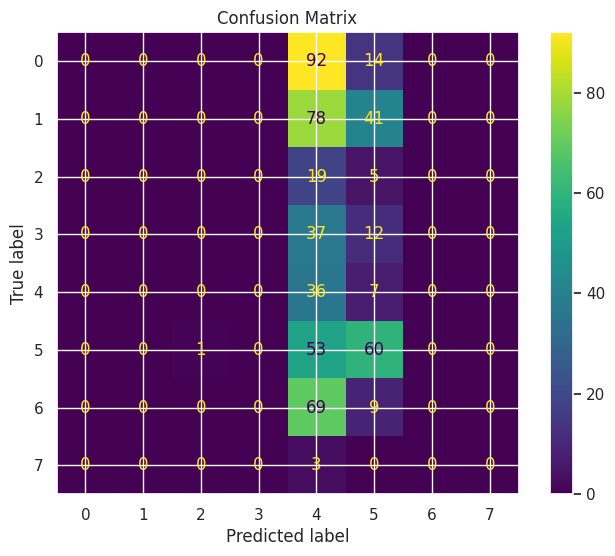

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_9
------------------------------
TRAIN
Accuracy: 0.5052
Precision: 0.5035
Recall: 0.5052
F1: 0.4757
Kappa: 0.3890
Error Rate: 0.4948

TEST
Accuracy: 0.1362
Precision: 0.2204
Recall: 0.1362
F1: 0.1109
Kappa: 0.0146
Error Rate: 0.8638
Gap (overfitting): 0.3690

CV
Mean: 0.5244
Std: 0.0194
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 2, 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



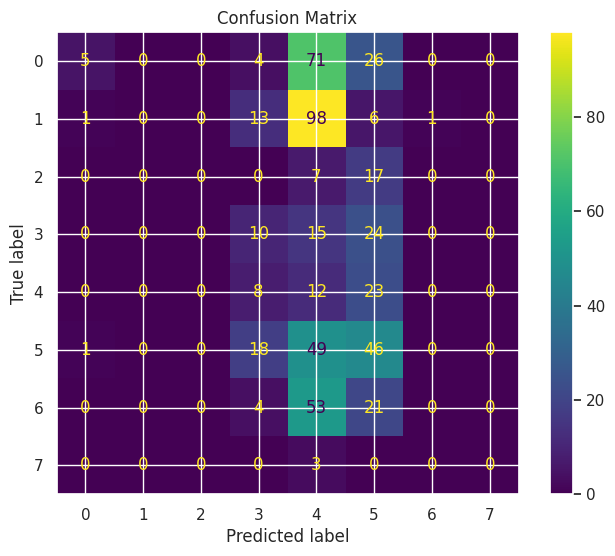

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_10
------------------------------
TRAIN
Accuracy: 0.2258
Precision: 0.0510
Recall: 0.2258
F1: 0.0832
Kappa: 0.0000
Error Rate: 0.7742

TEST
Accuracy: 0.1903
Precision: 0.0653
Recall: 0.1903
F1: 0.0869
Kappa: -0.0259
Error Rate: 0.8097
Gap (overfitting): 0.0355

CV
Mean: 0.2218
Std: 0.0160
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 2, 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



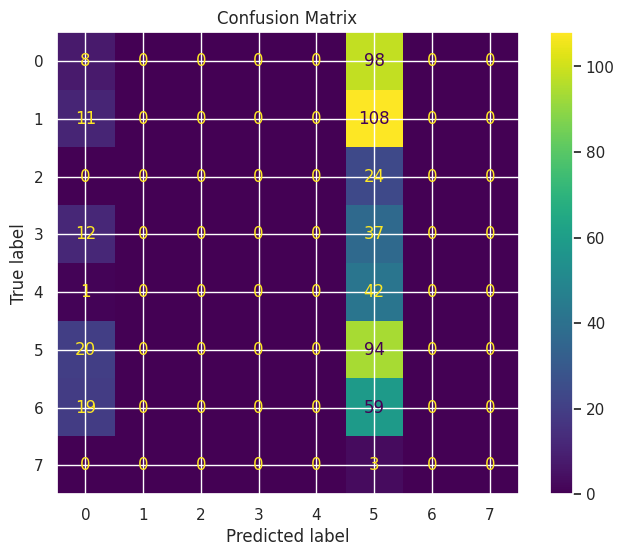

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_11
------------------------------
TRAIN
Accuracy: 0.5861
Precision: 0.6019
Recall: 0.5861
F1: 0.5796
Kappa: 0.4926
Error Rate: 0.4139

TEST
Accuracy: 0.0951
Precision: 0.2938
Recall: 0.0951
F1: 0.0330
Kappa: 0.0182
Error Rate: 0.9049
Gap (overfitting): 0.4909

CV
Mean: 0.5754
Std: 0.0267
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 2, 'dropout': 0.2, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



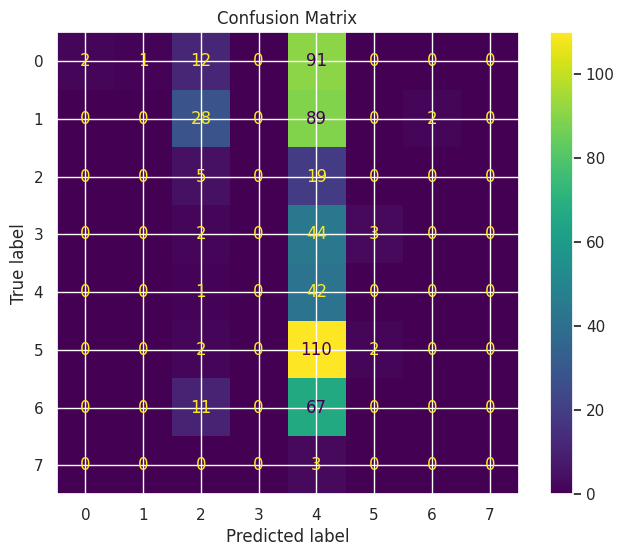

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_12
------------------------------
TRAIN
Accuracy: 0.4812
Precision: 0.4812
Recall: 0.4812
F1: 0.4651
Kappa: 0.3620
Error Rate: 0.5188

TEST
Accuracy: 0.0131
Precision: 0.0722
Recall: 0.0131
F1: 0.0127
Kappa: -0.0024
Error Rate: 0.9869
Gap (overfitting): 0.4681

CV
Mean: 0.5216
Std: 0.0078
------------------------------
Model params:
{'hidden_size': 8, 'num_layers': 1, 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



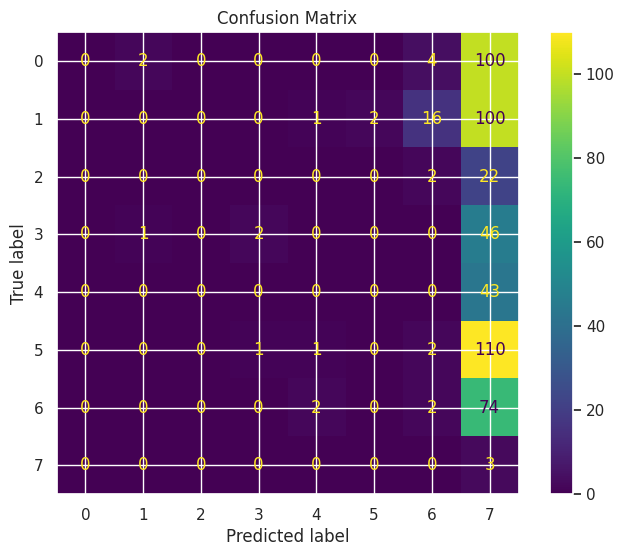

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_13
------------------------------
TRAIN
Accuracy: 0.5797
Precision: 0.6432
Recall: 0.5797
F1: 0.5792
Kappa: 0.4833
Error Rate: 0.4203

TEST
Accuracy: 0.1996
Precision: 0.0884
Recall: 0.1996
F1: 0.0884
Kappa: 0.0044
Error Rate: 0.8004
Gap (overfitting): 0.3800

CV
Mean: 0.5591
Std: 0.0215
------------------------------
Model params:
{'hidden_size': 16, 'num_layers': 2, 'dropout': 0.2, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'nonlinearity': 'tanh', 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



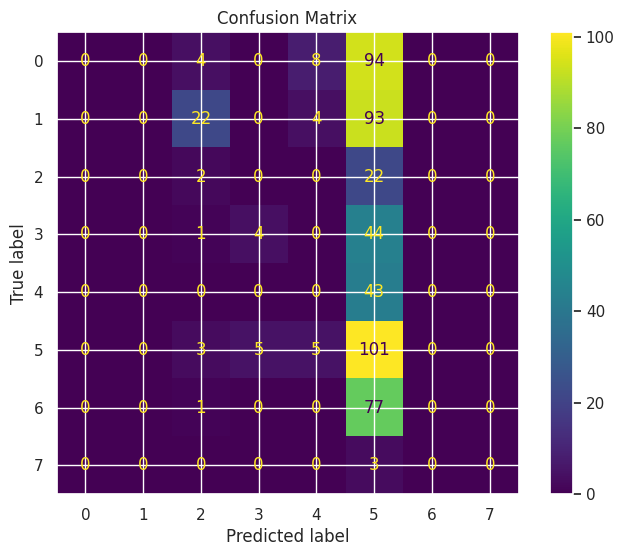

In [7]:
models_rnn_f4 = {}


# ============================================================
# 🔥 SGD com hidden=30 (base)
# ============================================================


models_rnn_f4['F3_1'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f4['F3_2'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.0005, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f4['F3_3'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.0001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f4['F3_4'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.1, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f4['F3_5'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f4['F3_6'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f4['F3_7'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    nonlinearity='tanh', solver='sgd', learning_rate=0.0005, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 SGD com hidden=50_25 (2 camadas)
# ============================================================


models_rnn_f4['F3_8'] = RNNClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f4['F3_9'] = RNNClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    nonlinearity='tanh', solver='sgd', learning_rate=0.0005, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f4['F3_10'] = RNNClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    nonlinearity='tanh', solver='sgd', learning_rate=0.0001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f4['F3_11'] = RNNClassifier(
    hidden_size=16, num_layers=2, dropout=0.2, fc_hidden_layers=(25,),
    nonlinearity='tanh', solver='sgd', learning_rate=0.001, momentum=0.9,
    epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (Adam)
# ============================================================


models_rnn_f4['F3_12'] = RNNClassifier(
    hidden_size=8, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)


models_rnn_f4['F3_13'] = RNNClassifier(
    hidden_size=16, num_layers=2, dropout=0.2, fc_hidden_layers=(25,),
    nonlinearity='tanh', solver='adam', learning_rate=0.0001,
    epochs=500, batch_size=32, random_state=42
)


main(models_rnn_f4, "rnn_fase_4")

In [4]:
class GRUClassifier(BaseEstimator, ClassifierMixin):
    """GRU (Gated Recurrent Unit) - Meio termo entre RNN e LSTM"""

    def __init__(self,
                 hidden_size=32,
                 num_layers=1,
                 dropout=0.2,
                 fc_hidden_layers=(16,),
                 input_size=None,
                 output_size=8,
                 solver='adam',           # ← ADICIONADO
                 learning_rate=0.001,
                 momentum=0.9,            # ← ADICIONADO
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.dropout = dropout
        self.fc_hidden_layers = fc_hidden_layers
        self.input_size = input_size
        self.output_size = output_size
        self.solver = solver              # ← NOVO
        self.learning_rate = learning_rate
        self.momentum = momentum          # ← NOVO
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class GRUModel(nn.Module):
            def __init__(self, input_size, hidden_size, num_layers, dropout,
                         fc_hiddens, output_size):
                super(GRUModel, self).__init__()

                self.gru = nn.GRU(
                    input_size=input_size,
                    hidden_size=hidden_size,
                    num_layers=num_layers,
                    batch_first=True,
                    dropout=dropout if num_layers > 1 else 0
                )

                self.gru_dropout = nn.Dropout(dropout)

                fc_layers = []
                prev_size = hidden_size

                for hidden in fc_hiddens:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc_layers = nn.Sequential(*fc_layers)

            def forward(self, x):
                x = x.unsqueeze(1)  # (batch, seq_len=1, features)
                gru_out, hidden = self.gru(x)
                last_hidden = hidden[-1]  # (batch, hidden_size)
                out = self.gru_dropout(last_hidden)
                out = self.fc_layers(out)
                return out

        return GRUModel(
            input_size=self.input_size,
            hidden_size=self.hidden_size,
            num_layers=self.num_layers,
            dropout=self.dropout,
            fc_hiddens=self.fc_hidden_layers,
            output_size=self.output_size
        )

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # ============================================================
        # ADAPTADO: Escolher otimizador baseado em self.solver
        # ============================================================
        if self.solver == 'adam':
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        elif self.solver == 'sgd':
            self.optimizer = optim.SGD(self.model.parameters(), lr=self.learning_rate, momentum=self.momentum)
        elif self.solver == 'rmsprop':
            self.optimizer = optim.RMSprop(self.model.parameters(), lr=self.learning_rate)
        else:
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)

        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            #if (epoch + 1) % 20 == 0:
               # print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'hidden_size': self.hidden_size,
            'num_layers': self.num_layers,
            'dropout': self.dropout,
            'fc_hidden_layers': self.fc_hidden_layers,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'solver': self.solver,           # ← NOVO
            'learning_rate': self.learning_rate,
            'momentum': self.momentum,       # ← NOVO
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state,
            'device': self.device
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

In [ ]:
models_gru = {}


models_gru['GRU_rmsprop'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_gru['GRU_adam'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_gru['GRU_sgd_momentum'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru['GRU_adam_lowLR'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_gru, "gru_experiments")

/tmp/ipykernel_3728/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)


In [ ]:
models_gru_f1 = {}


# ============================================================
# 1º MELHOR: GRU_sgd_momentum
# ============================================================


models_gru_f1['GRU_sgd_30'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f1['GRU_sgd_50'] = GRUClassifier(
    hidden_size=16, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# 2 camadas GRU + FC
models_gru_f1['GRU_sgd_50_25'] = GRUClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# Regularização (dropout)
models_gru_f1['GRU_sgd_reg1e3'] = GRUClassifier(
    hidden_size=16, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f1['GRU_sgd_reg5e3'] = GRUClassifier(
    hidden_size=16, num_layers=1, dropout=0.5, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 2º MELHOR: GRU_rmsprop
# ============================================================


models_gru_f1['GRU_rmsprop_30'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_gru_f1['GRU_rmsprop_50'] = GRUClassifier(
    hidden_size=16, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_gru_f1['GRU_rmsprop_50_25'] = GRUClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_gru_f1['GRU_rmsprop_reg1e3'] = GRUClassifier(
    hidden_size=16, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 3º MELHOR: GRU_adam_lowLR
# ============================================================


models_gru_f1['GRU_adam_lowLR_30'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_gru_f1['GRU_adam_lowLR_50'] = GRUClassifier(
    hidden_size=16, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_gru_f1['GRU_adam_lowLR_50_25'] = GRUClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_gru_f1['GRU_adam_lowLR_reg1e3'] = GRUClassifier(
    hidden_size=16, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_gru_f1, "gru_fase_1")

In [ ]:
models_gru_f2 = {}


# ============================================================
# OTIMIZADORES
# ============================================================


models_gru_f2['GRU_solver_adam'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_gru_f2['GRU_solver_sgd'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f2['GRU_solver_rmsprop'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ARQUITETURAS
# ============================================================


# hidden_size = 10
models_gru_f2['GRU_arch_10'] = GRUClassifier(
    hidden_size=10, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# hidden_size = 30
models_gru_f2['GRU_arch_30'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# hidden_size = 50
models_gru_f2['GRU_arch_50'] = GRUClassifier(
    hidden_size=16, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# 2 camadas GRU + FC (50_25)
models_gru_f2['GRU_arch_50_25'] = GRUClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# REGULARIZAÇÃO
# ============================================================


models_gru_f2['GRU_dropout_0'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_gru_f2['GRU_dropout_1e-1'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.1, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_gru_f2['GRU_dropout_1e-1.5'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_gru_f2['GRU_dropout_1e-1.8'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_gru_f2, "gru_fase_2")

In [ ]:
models_gru_f3 = {}


# ============================================================
# 🔥 BASE TOP (SGD)
# ============================================================


models_gru_f3['F2_1'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f3['F2_2'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_gru_f3['F2_3'] = GRUClassifier(
    hidden_size=16, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f3['F2_4'] = GRUClassifier(
    hidden_size=16, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_gru_f3['F2_5'] = GRUClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f3['F2_6'] = GRUClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (ADAM)
# ============================================================


models_gru_f3['F2_7'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_gru_f3['F2_8'] = GRUClassifier(
    hidden_size=16, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_gru_f3['F2_9'] = GRUClassifier(
    hidden_size=16, num_layers=2, dropout=0.2, fc_hidden_layers=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 EXTRA: Regularização para SGD
# ============================================================


models_gru_f3['F2_10'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f3['F2_11'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f3['F2_12'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


main(models_gru_f3, "gru_fase_3")


In [ ]:
models_gru_f4 = {}


# ============================================================
# 🔥 SGD com hidden=30 (base)
# ============================================================


models_gru_f4['F3_1'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f4['F3_2'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f4['F3_3'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f4['F3_4'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.1, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f4['F3_5'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f4['F3_6'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.3, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f4['F3_7'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 SGD com hidden=50_25 (2 camadas)
# ============================================================


models_gru_f4['F3_8'] = GRUClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f4['F3_9'] = GRUClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f4['F3_10'] = GRUClassifier(
    hidden_size=16, num_layers=2, dropout=0.0, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_gru_f4['F3_11'] = GRUClassifier(
    hidden_size=16, num_layers=2, dropout=0.2, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (Adam)
# ============================================================


models_gru_f4['F3_12'] = GRUClassifier(
    hidden_size=8, num_layers=1, dropout=0.2, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_gru_f4['F3_13'] = GRUClassifier(
    hidden_size=16, num_layers=2, dropout=0.2, fc_hidden_layers=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_gru_f4, "gru_fase_4")